# Análisis de sentimiento y búsqueda por aspectos en reseñas de hoteles de lujo

**Representaciones dispersas (BoW / TF-IDF), distribuidas (Word2Vec) y recuperación de información (BM25 + Sentence-BERT)**

Isabel Cristina Morales Parra · Jaime Esteban Bejarano Caldas

Maestría en Analítica Aplicada e Inteligencia Artificial, Universidad de La Sabana
Procesamiento de Lenguaje Natural · Trabajo final · Profesor: Andrés Rosso, PhD
Conjunto de datos: `LuxuryHotels.csv` · Noviembre de 2026

---

### Preguntas del trabajo

1. **¿Qué palabras caracterizan una opinión negativa frente a una positiva?**
2. **¿Qué tan bien se predice la polaridad** con representaciones dispersas (binaria, BoW, TF-IDF) y distribuidas (Word2Vec)?
3. **¿Cómo encontrar los comentarios sobre un aspecto del servicio** (por ejemplo "piscina" o "buffet"), en cualquier idioma, y saber qué se critica de él?

### Hallazgos principales

| # | Hallazgo | Evidencia |
|:--|:--|:--|
| 1 | TF-IDF con bigramas es el mejor clasificador | F1-macro de 0,916 (IC95 [0,890; 0,939]); recall de negativas de 0,862 (4.2) |
| 2 | La queja típica es contra la categoría, la respuesta y el precio | *star hotel* 9,9 veces, *told* 13,6 veces y *paid* 12,7 veces más frecuentes en negativas (5.4) |
| 3 | El paso de 4★ a 5★ depende de las personas | *thank, helped, attentive, team* frente a *average, old, dated* (5.5) |
| 4 | Word2Vec gana solo con pocas etiquetas | 0,831 frente a 0,587 con 250 reseñas; TF-IDF lo supera desde unas 2.000 (6.5) |
| 5 | Las proyecciones semánticas medían, sobre todo, sentimiento general | Correlación entre ejes de 0,904; al ortogonalizar, la correlación con la calificación cae entre 42 % y 63 % (7.4) |
| 6 | No hay deriva temporal que dañe el modelo | Entrenado con 2014–2021: 0,931 en 2022–2024 (8.2) |
| 7 | Cada buscador gana en un idioma | MAP@10 en inglés: BM25 0,894; en español: Sentence-BERT 0,789 frente a 0,349 de BM25; sistema automático 0,784 global (9.7) |
| 8 | El wifi es un dolor oculto | 19,2 % de frases negativas, aunque solo el 8,1 % de esas reseñas tiene 1–2★ (9.6) |

### Estructura del notebook

| Sección | Contenido | Bloque del curso |
|:--|:--|:--|
| 0 | Configuración | — |
| 1 | Datos y preparación: duplicados, idioma, variable objetivo, particiones | Fundamentos |
| 2 | Análisis exploratorio textual | Fundamentos |
| 3 | Normalización y limpieza | Fundamentos |
| 4 | Clasificación con representaciones dispersas | Fundamentos |
| 5 | Palabras que caracterizan cada polaridad | Fundamentos |
| 6 | Word2Vec del dominio hotelero | Deep NLP (embeddings) |
| 7 | Proyecciones semánticas | Deep NLP (embeddings) |
| 8 | Evaluación final y análisis de errores | Fundamentos |
| 9 | Buscador de comentarios por aspecto y evaluación con MAP | Information Retrieval |
| 10 | Conclusiones, limitaciones y trabajo futuro | — |

### Cambios respecto al anteproyecto

| Tema | Anteproyecto | Este trabajo | Motivo |
|:--|:--|:--|:--|
| Texto con dos calificaciones | Se conserva una ocurrencia | Se eliminan sus 3 copias | No es una reseña: es `#NAME?`, un error de Excel al exportar (sección 1.2) |
| Idioma | "Las reseñas están en inglés" | Se detecta el idioma y se modela solo el inglés; el buscador usa todos los idiomas | Cerca del 4 % del corpus está en otros idiomas (sección 1.3) |
| Reseñas cortas | 123 reseñas con menos de 10 palabras | Se retira el hallazgo | Eran reseñas en japonés y chino, que no separan palabras con espacios |
| Escenario B (tres clases) | Complementario | Pasa a trabajo futuro | Alcance; la clase neutral es el 5 % y aporta poco a las preguntas |
| Nombres propios | No contemplado | Se enmascaran lugares, hoteles y personas en el clasificador | Sin ese control, "nepal" o "radisson" aparecen como palabras de sentimiento (sección 5) |
| Word2Vec | Analogías como evaluación central | Vecinos, término discordante y PCA; pocas analogías | La presentación del curso advierte que el paralelogramo solo funciona en casos acotados |
| Proyecciones semánticas | Cuatro ejes | Dos ejes: personal y limpieza, corregidos por el sentimiento general | Las anclas negativas de comida casi no aparecen y las de precio son ambiguas (sección 7.1) |
| Buscador | No contemplado | BM25, expansión con Word2Vec, Sentence-BERT multilingüe y fusión RRF, evaluados con MAP | Aplica el bloque de Information Retrieval del curso |

# 0. Configuración

Todas las rutas son relativas a la raíz del repositorio (el notebook funciona tanto desde `notebooks/` como desde la raíz):

- `data/LuxuryHotels.csv`: el conjunto de datos.
- `data/anotaciones/`: juicios de relevancia y frases de validación que llena el equipo.
- `figures/` y `results/`: las gráficas y tablas que genera este notebook.
- `modelos/paraphrase-multilingual-MiniLM-L12-v2/`: el modelo Sentence-BERT multilingüe. Si la carpeta no existe, se descarga de Hugging Face.
- `cache/`: resultados costosos (idioma detectado, Word2Vec, embeddings). Si se borra, se recalculan.

In [1]:
# En Colab o en un entorno nuevo, descomente la línea siguiente:
# !pip install -q pandas scikit-learn gensim nltk langdetect wordcloud seaborn sentence-transformers openpyxl

import os, re, time, math, random, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as sp
from scipy.stats import spearmanr
from IPython.display import display, Markdown

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import (f1_score, balanced_accuracy_score, precision_score, recall_score,
                             accuracy_score, confusion_matrix, roc_auc_score, cohen_kappa_score)
from sklearn.decomposition import PCA

import nltk
from nltk import pos_tag
from nltk.stem import WordNetLemmatizer
from langdetect import detect, DetectorFactory
from gensim.models import Word2Vec
from wordcloud import WordCloud

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', message='IProgress not found')   # aviso cosmético de tqdm en Jupyter

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
DetectorFactory.seed = 0          # langdetect es aleatorio si no se fija la semilla

BASE = Path.cwd()
ROOT = BASE.parent if BASE.name == 'notebooks' else BASE
DATA_PATH = ROOT / 'data' / 'LuxuryHotels.csv'
assert DATA_PATH.exists(), 'No se encontró data/LuxuryHotels.csv en la raíz del repositorio'
CACHE, EVAL = ROOT / 'cache', ROOT / 'data' / 'anotaciones'
FIGURES, RESULTS = ROOT / 'figures', ROOT / 'results'
for d in (CACHE, EVAL, FIGURES, RESULTS):
    d.mkdir(parents=True, exist_ok=True)
SBERT_LOCAL = ROOT / 'modelos' / 'paraphrase-multilingual-MiniLM-L12-v2'
SBERT_NAME = str(SBERT_LOCAL) if (SBERT_LOCAL / 'modules.json').exists() else \
    'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2'

def guardar_figura(nombre):
    """Guarda la figura actual en figures/ y la muestra en el notebook."""
    plt.tight_layout()
    plt.savefig(FIGURES / f'{nombre}.png', dpi=150, bbox_inches='tight')
    plt.show()

for recurso in ['wordnet', 'omw-1.4', 'averaged_perceptron_tagger_eng']:
    nltk.download(recurso, quiet=True)

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold'})
COL = {'neg': '#c0504d', 'pos': '#4f81bd', 'neu': '#9e9e9e'}
pd.set_option('display.max_colwidth', 160)

import sklearn, gensim, sentence_transformers
print('Raíz del repositorio:', ROOT.name, '| datos:', DATA_PATH.relative_to(ROOT))
print('Modelo Sentence-BERT:', 'carpeta local' if SBERT_NAME == str(SBERT_LOCAL) else 'Hugging Face')
print(f'pandas {pd.__version__} | scikit-learn {sklearn.__version__} | gensim {gensim.__version__} | '
      f'nltk {nltk.__version__} | sentence-transformers {sentence_transformers.__version__}')

Raíz del repositorio: pln-resenas-hoteles-lujo | datos: data/LuxuryHotels.csv
Modelo Sentence-BERT: carpeta local
pandas 3.0.5 | scikit-learn 1.9.1 | gensim 4.4.0 | nltk 3.10.4 | sentence-transformers 6.3.0


# 1. Datos y preparación

## 1.1 Carga y estructura

El archivo trae cuatro columnas: `Review` (texto), `Rating` (1–5), `Bubbles` (la calificación en texto) y `YY` (año en dos dígitos). Se asume que `YY` corresponde a 2014–2024; el archivo no lo documenta.

In [2]:
raw = pd.read_csv(DATA_PATH)
print('Registros:', raw.shape[0], '| columnas:', list(raw.columns))
print('Valores nulos por columna:', raw.isna().sum().to_dict())

bubbles_num = raw['Bubbles'].str.extract(r'(\d+(?:\.\d+)?)')[0].astype(float)
print(f"Bubbles coincide con Rating en el {(bubbles_num == raw['Rating']).mean():.1%} de los registros -> se descarta")
raw['year'] = 2000 + raw['YY']
display(raw[['Review', 'Rating', 'Bubbles', 'YY']].head(3))

Registros: 18074 | columnas: ['Bubbles', 'Review', 'Rating', 'YY']
Valores nulos por columna: {'Bubbles': 0, 'Review': 0, 'Rating': 0, 'YY': 0}
Bubbles coincide con Rating en el 100.0% de los registros -> se descarta


,Review,Rating,Bubbles,YY
0,"It was late evening when we , a family of 3 , checked-in . Front office had 3 persons manning the counters, ,2 girls and a man. Smooth transition to our roo...",5,5.0 of 5 bubbles,22
1,"We had a very nice stay at Akama . Went here with my mom , dad and grand mom for Pashupatinath Darshan . They rooms were so neat and the service was at par ...",5,5.0 of 5 bubbles,22
2,"Hey you! Yes, you! If you are struggling to choose a hotel a hotel in Kathmandu (like I did), then you should absolutely read this review. In short, stay at...",5,5.0 of 5 bubbles,23


## 1.2 Duplicados y conflicto de etiqueta

Igual que en el taller de IMDB, se eliminan las reseñas repetidas: si una misma reseña cae en entrenamiento y en prueba, el modelo "ve el examen antes de presentarlo". Además, un texto aparece con calificaciones distintas, y se eliminan todas sus copias.

In [3]:
n_dup = int(raw.duplicated('Review').sum())
conf = raw.groupby('Review')['Rating'].nunique()
conf_txt = set(conf[conf > 1].index)
print(f'Textos repetidos: {n_dup} | textos con calificaciones contradictorias: {len(conf_txt)}')
display(raw[raw['Review'].isin(conf_txt)][['Rating', 'YY']].assign(Review=lambda d: raw.loc[d.index, 'Review'].str[:120]))

df = (raw[~raw['Review'].isin(conf_txt)]
      .drop_duplicates('Review')
      .drop(columns='Bubbles')
      .reset_index(drop=True))
df['doc_id'] = np.arange(len(df))
print(f'Corpus de trabajo: {len(df):,} reseñas únicas')

Textos repetidos: 97 | textos con calificaciones contradictorias: 1


,Rating,YY,Review
9256,1,19,#NAME?
10637,4,17,#NAME?
17034,5,23,#NAME?


Corpus de trabajo: 17,976 reseñas únicas


El texto "en conflicto" no es una reseña: es **`#NAME?`**, el error que muestra Excel cuando una celda empieza con `=`, `+` o `-` y la interpreta como fórmula. Aparece 3 veces, con calificaciones 1, 4 y 5. El texto original de esas reseñas se perdió al exportar el archivo, así que eliminarlas es la única opción.

## 1.3 Idioma

El anteproyecto suponía que todas las reseñas estaban en inglés. Se detecta el idioma de cada una con `langdetect` (semilla fija). La detección tarda alrededor de 30 segundos y se guarda en `cache/`.

In [4]:
f_idioma = CACHE / 'idioma.pkl'
if f_idioma.exists() and set(pd.read_pickle(f_idioma)['Review']) >= set(df['Review']):
    idioma = pd.read_pickle(f_idioma)
else:
    def detectar_idioma(t):
        try:
            return detect(t)
        except Exception:
            return 'desconocido'
    idioma = pd.DataFrame({'Review': df['Review'], 'lang': df['Review'].apply(detectar_idioma)})
    idioma.to_pickle(f_idioma)
df = df.merge(idioma.drop_duplicates('Review'), on='Review', how='left')
df['label3'] = pd.cut(df['Rating'], [0, 2, 3, 5], labels=['neg', 'neu', 'pos']).astype(str)

tabla_idioma = (df.assign(negativa=df['label3'].eq('neg'))
                  .groupby('lang').agg(reseñas=('Review', 'size'), negativas=('negativa', 'sum'))
                  .sort_values('reseñas', ascending=False))
tabla_idioma['% del corpus'] = (100 * tabla_idioma['reseñas'] / len(df)).round(2)
display(tabla_idioma.head(10))
n_en = int((df['lang'] == 'en').sum())
print(f"Inglés: {n_en:,} reseñas | otros idiomas: {len(df) - n_en:,} "
      f"({(len(df) - n_en) / len(df):.1%}), de ellas {int(((df['lang'] != 'en') & (df['label3'] == 'neg')).sum())} negativas")

# ¿De dónde salían las "123 reseñas con menos de 10 palabras" del anteproyecto?
df['n_palabras'] = df['Review'].str.split().str.len()
cortas = df[df['n_palabras'] < 10]
print(f'Reseñas con menos de 10 "palabras" (separadas por espacios): {len(cortas)} -> idiomas:',
      cortas['lang'].value_counts().to_dict())
print('Reseñas en inglés con menos de 10 palabras:', int(((df['lang'] == 'en') & (df['n_palabras'] < 10)).sum()))

,reseñas,negativas,% del corpus
lang,,,
en,17262,650,96.03
es,161,11,0.90
it,110,6,0.61
ja,102,4,0.57
de,92,5,0.51
fr,83,1,0.46
pt,49,0,0.27
ru,22,1,0.12
tr,21,1,0.12


Inglés: 17,262 reseñas | otros idiomas: 714 (4.0%), de ellas 31 negativas


Reseñas con menos de 10 "palabras" (separadas por espacios): 120 -> idiomas: {'ja': 100, 'zh-cn': 10, 'zh-tw': 7, 'ko': 2, 'th': 1}
Reseñas en inglés con menos de 10 palabras: 0


El 4,0 % del corpus (714 reseñas) está en otros idiomas, sobre todo español (161), italiano (110), japonés (102) y alemán (92); 31 de ellas son negativas. Las "reseñas cortas" del anteproyecto eran un artefacto: de las 120 con menos de 10 "palabras", 100 están en japonés y 17 en chino, idiomas que no separan las palabras con espacios. En inglés no hay ninguna reseña con menos de 10 palabras.

**Decisión.** El clasificador, el análisis exploratorio y Word2Vec usan solo las reseñas en inglés: las stop words, la lematización y los modelos son de inglés, y las pocas reseñas en otros idiomas serían ruido. El **buscador** (sección 9) sí usa todo el corpus, porque el modelo Sentence-BERT es multilingüe y el administrador necesita ver todos los comentarios sobre un aspecto.

## 1.4 Variable objetivo

`Rating` es ordinal: el orden importa, pero la distancia entre categorías no es homogénea. Se usan dos escenarios del anteproyecto:

| Escenario | Definición | Pregunta |
|:--|:--|:--|
| **A. Binario polar (principal)** | negativa = 1–2, positiva = 4–5, se excluye 3 | ¿La experiencia fue satisfactoria o no? |
| **C. Satisfacción plena** | excelente = 5, no excelente = 1–4 | ¿Qué separa una estadía excelente de una que solo es buena? |

El escenario B (tres clases) pasa a trabajo futuro.

In [5]:
en = df[df['lang'] == 'en'].copy()
A = en[en['label3'] != 'neu'].copy()
A['y'] = (A['label3'] == 'neg').astype(int)          # 1 = negativa: la clase de interés
en['yC'] = (en['Rating'] <= 4).astype(int)           # 1 = no excelente

dist = pd.DataFrame({
    'Rating': [1, 2, 3, 4, 5],
    'reseñas': [int((en['Rating'] == r).sum()) for r in [1, 2, 3, 4, 5]]})
dist['%'] = (100 * dist['reseñas'] / dist['reseñas'].sum()).round(1)
display(dist.set_index('Rating').T)
print(f"Escenario A: {len(A):,} reseñas | negativas {A['y'].sum()} ({A['y'].mean():.1%}) | razón ≈ {(1 - A['y'].mean()) / A['y'].mean():.0f}:1")
print(f"Escenario C: {len(en):,} reseñas | no excelentes {en['yC'].sum():,} ({en['yC'].mean():.1%})")

Rating,1,2,3,4,5
reseñas,339.0,311.0,825.0,2634.0,13153.0
%,2.0,1.8,4.8,15.3,76.2


Escenario A: 16,437 reseñas | negativas 650 (4.0%) | razón ≈ 24:1
Escenario C: 17,262 reseñas | no excelentes 4,109 (23.8%)


## 1.5 Particiones

- **Aleatoria estratificada 80/20** para los escenarios A y C (`random_state = 42`). Todos los hiperparámetros se eligen con validación cruzada dentro de entrenamiento; la prueba se usa una sola vez.
- **Temporal** (prueba de robustez del escenario A): se entrena con 2014–2021 y se prueba con 2022–2024.

In [6]:
tr_A, te_A = train_test_split(A.index, test_size=0.2, stratify=A['y'], random_state=RANDOM_STATE)
tr_C, te_C = train_test_split(en.index, test_size=0.2, stratify=en['yC'], random_state=RANDOM_STATE)
tr_T, te_T = A.index[A['YY'] <= 21], A.index[A['YY'] >= 22]

part = pd.DataFrame({
    'entrenamiento': [len(tr_A), len(tr_T), len(tr_C)],
    'negativas / no excelentes (entr.)': [A.loc[tr_A, 'y'].sum(), A.loc[tr_T, 'y'].sum(), en.loc[tr_C, 'yC'].sum()],
    'prueba': [len(te_A), len(te_T), len(te_C)],
    'negativas / no excelentes (prueba)': [A.loc[te_A, 'y'].sum(), A.loc[te_T, 'y'].sum(), en.loc[te_C, 'yC'].sum()]},
    index=['A aleatoria', 'A temporal (≤2021 / ≥2022)', 'C aleatoria'])
part['% clase de interés (prueba)'] = (100 * part.iloc[:, 3] / part['prueba']).round(1)
display(part)

,entrenamiento,negativas / no excelentes (entr.),prueba,negativas / no excelentes (prueba),% clase de interés (prueba)
A aleatoria,13149,520,3288,130,4.0
A temporal (≤2021 / ≥2022),8704,498,7733,152,2.0
C aleatoria,13809,3287,3453,822,23.8


# 2. Análisis exploratorio textual

Se trabaja sobre las reseñas en inglés. Para contar palabras se usa una tokenización simple (minúsculas y secuencias de letras) y una lista de stop words que **conserva las negaciones**, como en el taller de IMDB.

In [7]:
NEGATIONS_TO_KEEP = {'not', 'no', 'nor', 'never', 'none', 'nothing', 'nobody', 'neither', 'nowhere', 'cannot'}
CUSTOM_STOP_WORDS = set(ENGLISH_STOP_WORDS) - NEGATIONS_TO_KEEP
RE_WORD = re.compile(r"[a-z]+")

def tokens_simple(texto):
    return RE_WORD.findall(str(texto).lower())

en['tok_simple'] = en['Review'].apply(tokens_simple)
print(f"Tokens en inglés: {en['tok_simple'].str.len().sum():,} | mediana por reseña: {en['tok_simple'].str.len().median():.0f}")

Tokens en inglés: 1,560,391 | mediana por reseña: 59


## 2.1 Longitud de las reseñas

Rating,1,2,3,4,5
mediana,94.0,100.0,86.0,70.0,55.0
media,143.5,148.9,122.5,100.1,83.0
reseñas,339.0,311.0,825.0,2634.0,13153.0


Reseñas que terminan en '…' o '...' (texto cortado por la plataforma): 333 (1.9%) -> por calificación: {1: 10, 2: 5, 3: 18, 4: 49, 5: 251}


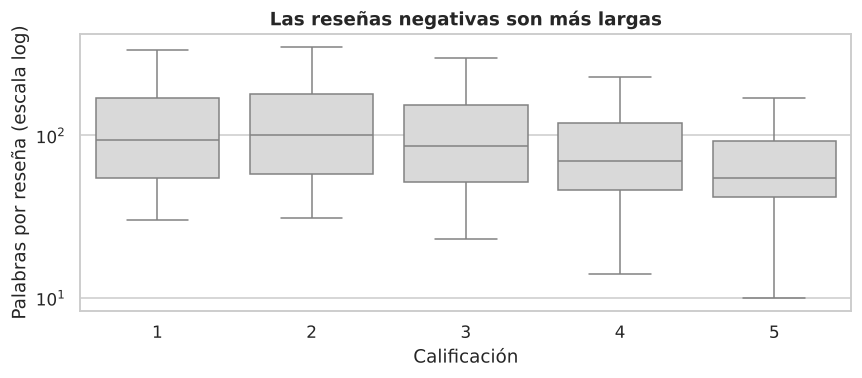

In [8]:
en['n_palabras'] = en['Review'].str.split().str.len()
long_tab = en.groupby('Rating')['n_palabras'].agg(['median', 'mean', 'size']).round(1)
long_tab.columns = ['mediana', 'media', 'reseñas']
display(long_tab.T)

en['truncada'] = en['Review'].str.contains(r'(?:\.\.\.|…)\s*$', regex=True)
print(f"Reseñas que terminan en '…' o '...' (texto cortado por la plataforma): {en['truncada'].sum()} "
      f"({en['truncada'].mean():.1%}) -> por calificación: {en.loc[en['truncada'], 'Rating'].value_counts().sort_index().to_dict()}")

fig, ax = plt.subplots(figsize=(8, 3.6))
sns.boxplot(data=en, x='Rating', y='n_palabras', ax=ax, color='#d9d9d9', showfliers=False)
ax.set_yscale('log'); ax.set_ylabel('Palabras por reseña (escala log)'); ax.set_xlabel('Calificación')
ax.set_title('Las reseñas negativas son más largas')
guardar_figura('01_longitud_por_calificacion')

La mediana pasa de 94–100 palabras en las reseñas de 1–2★ a 55 en las de 5★: quien se queja, cuenta la historia completa. Las 333 reseñas truncadas (1,9 %) son sobre todo de 5★ (251), así que el corte de la plataforma afecta poco a la clase negativa. El "…" se elimina en la limpieza.

## 2.2 Ley de Zipf y hapax legomena

Vocabulario: 27,356 palabras distintas | hapax legomena: 13,210 (48.3% del vocabulario, 0.85% de los tokens)
Pendiente log-log entre los rangos 10 y 10.000: -1.55 (Zipf ideal ≈ -1)
Las 10 más frecuentes: the (97,434), and (66,795), to (38,774), a (35,825), was (27,672), of (26,110), is (25,574), in (25,064), i (21,159), hotel (17,971)


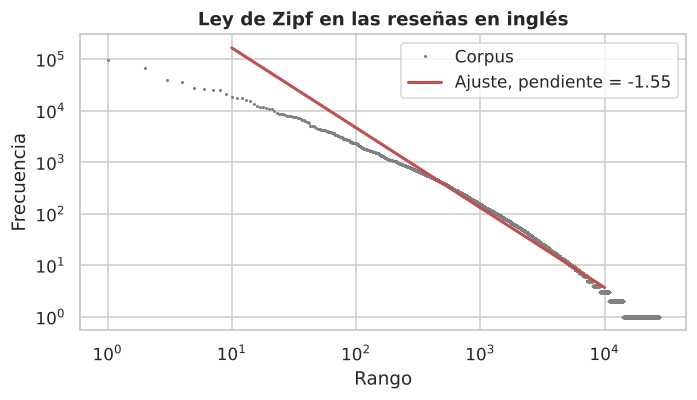

In [9]:
freq = Counter(w for toks in en['tok_simple'] for w in toks)
f_ord = np.array(sorted(freq.values(), reverse=True))
rangos = np.arange(1, len(f_ord) + 1)
sel = (rangos >= 10) & (rangos <= 10_000)
pendiente, intercepto = np.polyfit(np.log10(rangos[sel]), np.log10(f_ord[sel]), 1)
hapax = sum(1 for c in freq.values() if c == 1)
print(f'Vocabulario: {len(freq):,} palabras distintas | hapax legomena: {hapax:,} ({hapax / len(freq):.1%} del vocabulario, '
      f'{hapax / f_ord.sum():.2%} de los tokens)')
print(f'Pendiente log-log entre los rangos 10 y 10.000: {pendiente:.2f} (Zipf ideal ≈ -1)')
print('Las 10 más frecuentes:', ', '.join(f'{w} ({c:,})' for w, c in freq.most_common(10)))

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.loglog(rangos, f_ord, '.', ms=2, color='gray', label='Corpus')
ax.loglog(rangos[sel], 10 ** (intercepto + pendiente * np.log10(rangos[sel])), color=COL['neg'], lw=2,
          label=f'Ajuste, pendiente = {pendiente:.2f}')
ax.set_xlabel('Rango'); ax.set_ylabel('Frecuencia'); ax.set_title('Ley de Zipf en las reseñas en inglés'); ax.legend()
guardar_figura('02_ley_de_zipf')

El 48,3 % del vocabulario son hapax (palabras que aparecen una sola vez), pero esas palabras son apenas el 0,85 % de los tokens. Por eso `min_df = 3` en los vectorizadores elimina cerca de la mitad del vocabulario casi sin perder texto, y deja fuera sobre todo errores de tipeo y nombres raros. La pendiente de −1,55 es más pronunciada que la de Zipf ideal: en un corpus pequeño y de un solo dominio, la cola de palabras raras cae más rápido.

## 2.3 Palabras frecuentes por clase (escenario A)

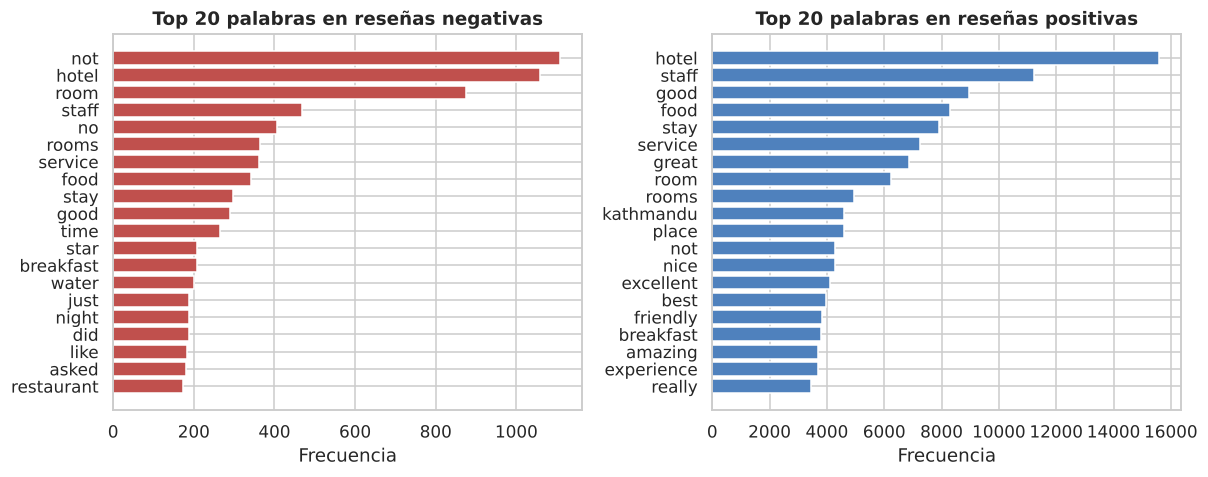

En el top 20 de ambas clases: ['breakfast', 'food', 'good', 'hotel', 'not', 'room', 'rooms', 'service', 'staff', 'stay']
Solo en negativas: ['asked', 'did', 'just', 'like', 'night', 'no', 'restaurant', 'star', 'time', 'water']
Solo en positivas: ['amazing', 'best', 'excellent', 'experience', 'friendly', 'great', 'kathmandu', 'nice', 'place', 'really']


In [10]:
def top_palabras(series_tokens, n=20):
    c = Counter(w for toks in series_tokens for w in toks if w not in CUSTOM_STOP_WORDS and len(w) > 1)
    return c.most_common(n)

top_neg = top_palabras(en.loc[A.index[A['y'] == 1], 'tok_simple'])
top_pos = top_palabras(en.loc[A.index[A['y'] == 0], 'tok_simple'])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, top, nombre, color in [(axes[0], top_neg, 'negativas', COL['neg']), (axes[1], top_pos, 'positivas', COL['pos'])]:
    w, c = zip(*top)
    ax.barh(list(w)[::-1], list(c)[::-1], color=color)
    ax.set_title(f'Top 20 palabras en reseñas {nombre}'); ax.set_xlabel('Frecuencia')
guardar_figura('03_palabras_frecuentes_por_clase')
s_neg, s_pos = {w for w, _ in top_neg}, {w for w, _ in top_pos}
print('En el top 20 de ambas clases:', sorted(s_neg & s_pos))
print('Solo en negativas:', sorted(s_neg - s_pos))
print('Solo en positivas:', sorted(s_pos - s_neg))

La frecuencia cruda no separa bien las clases: ambas hablan de *hotel*, *room* y *staff*. Por eso la sección 5 usa los coeficientes del clasificador, que miden cuánto **cambia** la probabilidad de ser negativa cuando aparece una palabra, y no cuántas veces aparece. Además, *kathmandu* aparece entre las palabras exclusivas de las positivas: es una primera señal de que los nombres de lugar se pueden confundir con sentimiento (sección 3.2).

## 2.4 Nubes de palabras

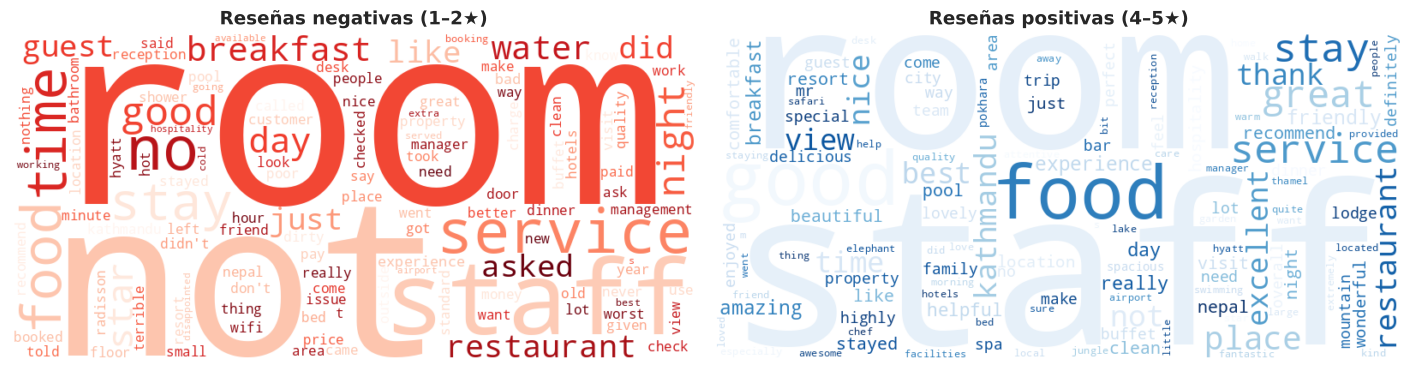

In [11]:
def nube(textos, titulo, ax, cmap):
    wc = WordCloud(width=800, height=380, background_color='white', stopwords=CUSTOM_STOP_WORDS | {'hotel'},
                   max_words=120, colormap=cmap, random_state=RANDOM_STATE, collocations=False)
    wc.generate(' '.join(textos).lower())
    ax.imshow(wc, interpolation='bilinear'); ax.axis('off'); ax.set_title(titulo)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
nube(A.loc[A['y'] == 1, 'Review'], 'Reseñas negativas (1–2★)', axes[0], 'Reds')
nube(A.loc[A['y'] == 0, 'Review'], 'Reseñas positivas (4–5★)', axes[1], 'Blues')
guardar_figura('04_nubes_de_palabras')

## 2.5 Composición por año

year,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
reseñas,1006.00,1011.00,1342.00,1580.00,1590.00,1780.00,417.00,703.00,1962.00,3069.00,2802.00
pct_neg,6.36,3.86,5.14,7.72,5.09,4.27,3.36,4.69,2.50,1.96,1.53
rating_medio,4.24,4.40,4.34,4.29,4.50,4.60,4.59,4.70,4.81,4.84,4.85


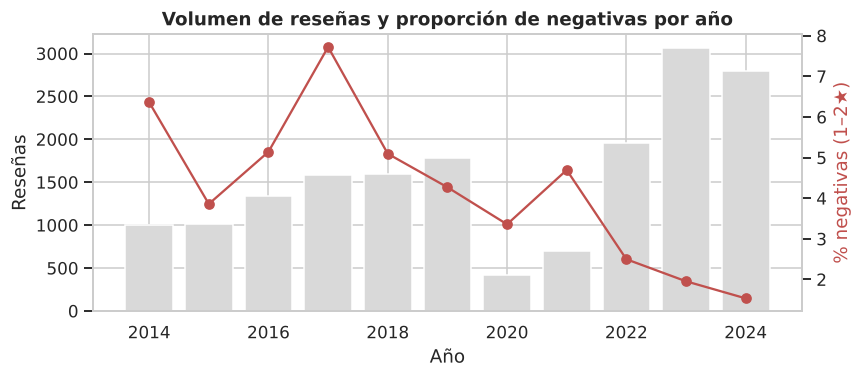

In [12]:
anual = en.groupby('year').agg(reseñas=('Review', 'size'),
                               pct_neg=('label3', lambda s: 100 * (s == 'neg').mean()),
                               rating_medio=('Rating', 'mean'))
display(anual.round(2).T)
fig, ax1 = plt.subplots(figsize=(8, 3.6))
ax1.bar(anual.index, anual['reseñas'], color='#d9d9d9'); ax1.set_ylabel('Reseñas'); ax1.set_xlabel('Año')
ax2 = ax1.twinx(); ax2.plot(anual.index, anual['pct_neg'], 'o-', color=COL['neg']); ax2.set_ylabel('% negativas (1–2★)', color=COL['neg'])
ax2.grid(False); ax1.set_title('Volumen de reseñas y proporción de negativas por año')
guardar_figura('05_resenas_y_negativas_por_anio')

La proporción de negativas baja del 7,72 % (2017) al 1,53 % (2024), y la calificación media sube de 4,24 (2014) a 4,85 (2024). En 2020 y 2021 el volumen cae a 417 y 703 reseñas, coherente con la pandemia. Como se advirtió en el anteproyecto, los datos no permiten separar una mejora real del servicio de un cambio en los hoteles reseñados o en la plataforma, así que la tendencia no se interpreta como evidencia de calidad. La validación temporal (8.2) mide si este cambio afecta al clasificador.

# 3. Normalización y limpieza

## 3.1 Función de limpieza

Se parte de `clean_text` del taller de IMDB (minúsculas, HTML, URLs, expansión de contracciones, solo letras, stop words fuera y **negaciones dentro**) y se agregan dos correcciones que salieron de este corpus:

1. **Contracciones sin apóstrofo.** Muchos huéspedes escriben "dont" o "wasnt". La regla `n't → not` no las captura, y "dont" terminaba como una palabra aparte con peso negativo en el modelo.
2. **Marcas de truncamiento.** Se elimina el "…" que deja la plataforma al cortar una reseña.

In [13]:
CONTRACCIONES = {'dont': 'do not', 'didnt': 'did not', 'doesnt': 'does not', 'wasnt': 'was not', 'isnt': 'is not',
                 'werent': 'were not', 'arent': 'are not', 'couldnt': 'could not', 'wouldnt': 'would not',
                 'shouldnt': 'should not', 'havent': 'have not', 'hasnt': 'has not', 'hadnt': 'had not',
                 'cant': 'can not', 'wont': 'will not', 'aint': 'is not'}
RE_CONTR = re.compile(r'\b(' + '|'.join(CONTRACCIONES) + r')\b')
RE_HTML = re.compile(r'<[^>]+>')
RE_URL = re.compile(r'https?://\S+|www\.\S+')

def normalizar(texto):
    """Pasos comunes a todos los usos: minúsculas, HTML, URLs, truncamiento y negaciones contraídas."""
    t = str(texto).lower().replace('’', "'").replace('…', ' ')
    t = RE_HTML.sub(' ', t)
    t = RE_URL.sub(' ', t)
    t = re.sub(r"\bwon't\b", 'will not', t)
    t = re.sub(r"\bcan't\b", 'can not', t)
    t = re.sub(r"n't\b", ' not', t)                       # didn't -> did not
    t = RE_CONTR.sub(lambda m: CONTRACCIONES[m.group(1)], t)   # dont -> do not
    return t

def clean_text(texto):
    """Texto para BoW / TF-IDF: solo letras, sin stop words, conservando negaciones."""
    return ' '.join(w for w in RE_WORD.findall(normalizar(texto)) if w not in CUSTOM_STOP_WORDS and len(w) > 1)

def tokens_w2v(texto):
    """Tokens para Word2Vec: limpieza mínima y CON stop words, porque la ventana necesita el contexto real."""
    return RE_WORD.findall(normalizar(texto))

ejemplo = "The room wasn't clean and the staff dont care!!! <br/> Visit www.hotel.com …"
print('Original:', ejemplo)
print('Limpio:  ', clean_text(ejemplo))
print('Word2Vec:', tokens_w2v(ejemplo))

en['clean'] = en['Review'].apply(clean_text)
en['tok_w2v'] = en['Review'].apply(tokens_w2v)
print('Reseñas vacías tras limpiar:', int((en['clean'].str.len() == 0).sum()))

Original: The room wasn't clean and the staff dont care!!! <br/> Visit www.hotel.com …
Limpio:   room not clean staff not care visit
Word2Vec: ['the', 'room', 'was', 'not', 'clean', 'and', 'the', 'staff', 'do', 'not', 'care', 'visit']


Reseñas vacías tras limpiar: 0


## 3.2 Nombres propios: lugares, hoteles y personas

El corpus no trae identificador de hotel, pero los nombres aparecen en el texto. Si un hotel concentra quejas, su nombre se vuelve una "palabra negativa" que no dice nada sobre el servicio y no generaliza a otros hoteles. Lo mismo pasa con ciudades o con los nombres del personal que los huéspedes agradecen.

Se detectan sin etiquetas: una palabra se considera nombre propio si aparece al menos 15 veces y en el 80 % de los casos con mayúscula inicial, **sin contar la primera palabra de cada oración**. En el clasificador esas palabras se enmascaran (se eliminan del texto).

In [14]:
def detectar_nombres_propios(textos, min_freq=15, umbral=0.8):
    mayus, total = Counter(), Counter()
    for t in textos:
        for oracion in re.split(r'(?<=[.!?])\s+', str(t)):
            palabras = re.findall(r'[A-Za-z]+', oracion)
            for w in palabras[1:]:                       # se ignora la primera palabra de la oración
                lw = w.lower()
                total[lw] += 1
                mayus[lw] += w[0].isupper()
    nombres = [w for w in total if total[w] >= min_freq and mayus[w] / total[w] >= umbral
               and w not in CUSTOM_STOP_WORDS and len(w) > 2]
    return sorted(nombres, key=lambda w: -total[w])

NOMBRES_PROPIOS = detectar_nombres_propios(en['Review'])
NP_SET = set(NOMBRES_PROPIOS)
print(f'Nombres propios detectados: {len(NOMBRES_PROPIOS)}')
print('Los 40 más frecuentes:', ', '.join(NOMBRES_PROPIOS[:40]))

def enmascarar(texto_limpio):
    return ' '.join(w for w in texto_limpio.split() if w not in NP_SET)

en['texto_modelo'] = en['clean'].apply(enmascarar)

Nombres propios detectados: 304
Los 40 más frecuentes: kathmandu, nepal, pokhara, hyatt, thamel, nepali, indian, marriott, nepalese, annapurna, yeti, yak, chitwan, everest, gokarna, dwarika, radisson, himalayas, chinese, tops, india, kasara, durbar, glacier, himalayan, ktm, mystic, english, katmandu, tharu, nagarkot, raj, sunil, krishna, mahal, prakash, sarangkot, manish, begnas, rohit


Se detectan 304 nombres propios: ciudades y lugares (*kathmandu, pokhara, thamel, chitwan*), hoteles y cadenas (*hyatt, marriott, radisson, dwarika, yak, yeti*), nacionalidades (*indian, chinese, english*) y nombres del personal (*sunil, krishna, prakash, manish*). Retirar las nacionalidades tiene una ventaja adicional: el modelo no puede asociar el sentimiento con el origen de los huéspedes.

## 3.3 Lematización

Se lematiza con WordNet (NLTK) usando la etiqueta gramatical de cada palabra. El etiquetado se hace sobre la secuencia completa, antes de quitar las stop words, para que el etiquetador vea oraciones reales. Tarda alrededor de 35 segundos.

In [15]:
LEM = WordNetLemmatizer()
POS_WN = {'J': 'a', 'V': 'v', 'N': 'n', 'R': 'r'}

def lematizar(tokens):
    return ' '.join(LEM.lemmatize(w, POS_WN.get(p[0], 'n')) for w, p in pos_tag(tokens)
                    if w not in CUSTOM_STOP_WORDS and len(w) > 1)

f_lemas = CACHE / 'lemas.pkl'
if f_lemas.exists() and set(pd.read_pickle(f_lemas)['Review']) >= set(en['Review']):
    lemas = pd.read_pickle(f_lemas)
else:
    lemas = pd.DataFrame({'Review': en['Review'], 'clean_lem': en['tok_w2v'].apply(lematizar)})
    lemas.to_pickle(f_lemas)
en['clean_lem'] = en['Review'].map(lemas.drop_duplicates('Review').set_index('Review')['clean_lem'])
en['texto_modelo_lem'] = en['clean_lem'].apply(enmascarar)
print('Ejemplo:', en['clean'].iloc[3][:110])
print('Lemas:  ', en['clean_lem'].iloc[3][:110])

Ejemplo: hello planning visit hotel never think best hotels awesome hospitality available town worst experience twice w
Lemas:   hello plan visit hotel never think best hotel awesome hospitality available town bad experience twice weed tim


El ejemplo muestra un efecto no deseado: WordNet convierte el superlativo *worst* en su lema *bad*. Para clasificar sentimiento, esa fusión borra la intensidad, que es justamente la señal.

## 3.4 Efecto de la limpieza sobre el vocabulario

In [16]:
def resumen_vocab(series_tokens):
    c = Counter(w for toks in series_tokens for w in toks)
    return {'vocabulario': len(c), 'tokens': sum(c.values()), 'hapax': sum(1 for v in c.values() if v == 1)}

vocab_tab = pd.DataFrame({
    'Original (minúsculas, separado por espacios)': resumen_vocab(en['Review'].str.lower().str.split()),
    'Solo letras': resumen_vocab(en['tok_simple']),
    'Limpio (sin stop words, con negaciones)': resumen_vocab(en['clean'].str.split()),
    'Limpio + nombres propios enmascarados': resumen_vocab(en['texto_modelo'].str.split()),
    'Limpio + lematizado + enmascarado': resumen_vocab(en['texto_modelo_lem'].str.split())}).T
vocab_tab['% vocabulario vs original'] = (100 * vocab_tab['vocabulario'] / vocab_tab['vocabulario'].iloc[0]).round(1)
display(vocab_tab)

,vocabulario,tokens,hapax,% vocabulario vs original
"Original (minúsculas, separado por espacios)",69023,1551468,44690,100.0
Solo letras,27356,1560391,13210,39.6
"Limpio (sin stop words, con negaciones)",27008,758701,13193,39.1
Limpio + nombres propios enmascarados,26704,725291,13193,38.7
Limpio + lematizado + enmascarado,22930,725626,11974,33.2


Separar por espacios deja 69.023 "palabras" distintas, porque la puntuación queda pegada ("room," y "room." cuentan como distintas). Quedarse solo con letras baja el vocabulario a 27.356. Sin stop words, los tokens se reducen a menos de la mitad (758.701 de 1.551.468) y se conserva el 39,1 % del vocabulario. La lematización lo lleva a 22.930 términos (33,2 %).

## 3.5 Bigramas con negación

Conservar las negaciones permite que aparezcan bigramas como "not clean". Se cuentan sobre el texto ya limpio, con `stop_words=None`, para no volver a borrarlas.

In [17]:
def top_bigramas_negacion(textos, n=12):
    cv = CountVectorizer(ngram_range=(2, 2), min_df=3)
    X = cv.fit_transform(textos)
    s = pd.Series(np.asarray(X.sum(0)).ravel(), index=cv.get_feature_names_out())
    s = s[[b.split()[0] in {'not', 'no', 'never'} for b in s.index]]
    return s.sort_values(ascending=False).head(n)

bn = top_bigramas_negacion(en.loc[A.index[A['y'] == 1], 'texto_modelo'])
bp = top_bigramas_negacion(en.loc[A.index[A['y'] == 0], 'texto_modelo'])
display(pd.DataFrame({'negativas': [f'{b} ({c})' for b, c in bn.items()],
                      'positivas': [f'{b} ({c})' for b, c in bp.items()]}))

,negativas,positivas
0,not recommend (53),not wait (122)
1,not work (47),not far (121)
2,not good (40),not want (113)
3,not working (37),not miss (106)
4,not worth (30),not good (93)
5,not know (28),not know (86)
6,not stay (24),not forget (86)
7,not care (22),not sure (81)
8,not clean (20),not stay (80)
9,not expect (19),not expect (79)


En las negativas, las negaciones forman quejas: *not recommend* (53), *not work* (47), *not worth* (30), *not clean* (20). En las positivas, la misma palabra expresa entusiasmo: *not wait* (122, de "can't wait to return"), *not miss* (106), *not disappointed* (72). Esto confirma dos decisiones del taller de IMDB: conservar las negaciones y usar bigramas, porque *not* sola no es sinónimo de queja.

### Qué representación usa cada parte

| Columna | Contenido | Se usa en |
|:--|:--|:--|
| `texto_modelo` | Limpio, sin stop words, con negaciones, sin nombres propios | Binaria, BoW, TF-IDF y clasificador |
| `texto_modelo_lem` | Lo mismo, lematizado | Experimento de lematización (4.4) |
| `tok_w2v` | Limpieza mínima, con stop words | Word2Vec (6) y proyecciones (7) |
| `tokens_ir` | `[a-z0-9]+` sin stop words, como en la sesión de IR | BM25 sobre todo el corpus (9) |

# 4. Clasificación con representaciones dispersas (escenario A)

Se entrena una regresión logística con `class_weight='balanced'` sobre cada representación. Con un desbalance de 24:1, un modelo que siempre diga "positiva" acierta el 96 %. Por eso las métricas principales son el **F1-macro**, la **exactitud balanceada** y la **precisión y el recall de la clase negativa**. La exactitud se reporta solo como referencia.

El hiperparámetro `C` se elige con validación cruzada estratificada de 5 particiones **dentro de entrenamiento**. Sobre la prueba se calcula un intervalo de confianza del 95 % por bootstrap (1.000 remuestreos), porque la prueba solo tiene 130 negativas y una diferencia de un punto puede ser ruido.

In [18]:
for c in ['texto_modelo', 'texto_modelo_lem', 'clean', 'n_palabras', 'tok_w2v']:
    A[c] = en.loc[A.index, c]
y_tr, y_te = A.loc[tr_A, 'y'].values, A.loc[te_A, 'y'].values
CV5 = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

def metricas(y, pred):
    return {'F1-macro': f1_score(y, pred, average='macro'),
            'Exactitud balanceada': balanced_accuracy_score(y, pred),
            'Precisión neg.': precision_score(y, pred, zero_division=0),
            'Recall neg.': recall_score(y, pred, zero_division=0),
            'Exactitud': accuracy_score(y, pred)}

def ic_bootstrap(y, pred, B=1000, seed=RANDOM_STATE):
    """Intervalo del 95 % para F1-macro y recall de la clase 1, remuestreando la prueba con reemplazo."""
    rng = np.random.RandomState(seed)
    y, pred = np.asarray(y), np.asarray(pred)
    f, r = [], []
    for _ in range(B):
        i = rng.randint(0, len(y), len(y))
        f.append(f1_score(y[i], pred[i], average='macro'))
        r.append(recall_score(y[i], pred[i], zero_division=0))
    return np.percentile(f, [2.5, 97.5]), np.percentile(r, [2.5, 97.5])

RESULTADOS = []
def registrar(nombre, y, pred, cv=np.nan, C=np.nan):
    m = metricas(y, pred)
    (f_lo, f_hi), (r_lo, r_hi) = ic_bootstrap(y, pred)
    RESULTADOS.append({'Modelo': nombre, 'C': C, 'F1-macro CV': cv, **m,
                       'IC95 F1-macro': f'[{f_lo:.3f}, {f_hi:.3f}]', 'IC95 recall neg.': f'[{r_lo:.3f}, {r_hi:.3f}]'})
    return m

def tabla_resultados(filtro=None):
    t = pd.DataFrame(RESULTADOS).set_index('Modelo')
    if filtro is not None:
        t = t.loc[filtro]
    return t.style.format({c: '{:.3f}' for c in ['F1-macro CV', 'F1-macro', 'Exactitud balanceada', 'Precisión neg.',
                                                  'Recall neg.', 'Exactitud']} | {'C': '{:g}'}, na_rep='—')

## 4.1 Líneas base

Dos referencias mínimas. La primera, un modelo que siempre predice "positiva". La segunda, una regresión logística que **solo ve la longitud** de la reseña. La sección 2.1 mostró que las negativas son más largas, y esta línea base mide cuánto de la tarea se resuelve con esa señal indirecta.

In [19]:
registrar('Línea base: siempre positiva', y_te, np.zeros_like(y_te))
X_len = np.log1p(A['n_palabras'].values).reshape(-1, 1)
lr_len = LogisticRegression(class_weight='balanced').fit(X_len[A.index.get_indexer(tr_A)], y_tr)
registrar('Línea base: solo longitud', y_te, lr_len.predict(X_len[A.index.get_indexer(te_A)]))
tabla_resultados()

,C,F1-macro CV,F1-macro,Exactitud balanceada,Precisión neg.,Recall neg.,Exactitud,IC95 F1-macro,IC95 recall neg.
Modelo,,,,,,,,,
Línea base: siempre positiva,—,—,0.490,0.500,0.000,0.000,0.960,"[0.488, 0.492]","[0.000, 0.000]"
Línea base: solo longitud,—,—,0.456,0.574,0.058,0.454,0.685,"[0.441, 0.470]","[0.365, 0.544]"


"Siempre positiva" logra una exactitud de 0,960 con un F1-macro de 0,490: es la trampa del desbalance. La longitud sola llega a una exactitud balanceada de 0,574 y a un F1-macro de 0,456, una señal débil. Si un modelo de texto supera ampliamente estas cifras, no lo está haciendo por la longitud de la reseña.

## 4.2 Binaria, BoW y TF-IDF

In [20]:
REPRESENTACIONES = {
    'Binaria (unigramas)': CountVectorizer(binary=True, min_df=3),
    'BoW (unigramas)': CountVectorizer(min_df=3),
    'TF-IDF (unigramas)': TfidfVectorizer(min_df=3, sublinear_tf=True),
    'TF-IDF (uni + bigramas)': TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.95, sublinear_tf=True)}

def ajustar(vectorizador, columna='texto_modelo', datos=A, idx_tr=tr_A, idx_te=te_A, ycol='y', grid=(1, 4, 16, 64)):
    pipe = Pipeline([('vec', vectorizador), ('clf', LogisticRegression(class_weight='balanced', max_iter=5000))])
    gs = GridSearchCV(pipe, {'clf__C': list(grid)}, scoring='f1_macro', cv=CV5, n_jobs=-1)
    gs.fit(datos.loc[idx_tr, columna], datos.loc[idx_tr, ycol])
    return gs, gs.predict(datos.loc[idx_te, columna])

MODELOS = {}
t0 = time.time()
for nombre, vec in REPRESENTACIONES.items():
    gs, pred = ajustar(vec)
    MODELOS[nombre] = gs.best_estimator_
    registrar(nombre, y_te, pred, cv=gs.best_score_, C=gs.best_params_['clf__C'])
print(f'Tiempo: {time.time() - t0:.0f} s')
tabla_resultados()

Tiempo: 33 s


,C,F1-macro CV,F1-macro,Exactitud balanceada,Precisión neg.,Recall neg.,Exactitud,IC95 F1-macro,IC95 recall neg.
Modelo,,,,,,,,,
Línea base: siempre positiva,—,—,0.490,0.500,0.000,0.000,0.960,"[0.488, 0.492]","[0.000, 0.000]"
Línea base: solo longitud,—,—,0.456,0.574,0.058,0.454,0.685,"[0.441, 0.470]","[0.365, 0.544]"
Binaria (unigramas),16,0.896,0.885,0.877,0.798,0.762,0.983,"[0.854, 0.914]","[0.686, 0.837]"
BoW (unigramas),1,0.882,0.903,0.918,0.786,0.846,0.985,"[0.876, 0.929]","[0.781, 0.907]"
TF-IDF (unigramas),64,0.903,0.913,0.919,0.821,0.846,0.987,"[0.887, 0.935]","[0.788, 0.906]"
TF-IDF (uni + bigramas),16,0.912,0.916,0.927,0.818,0.862,0.987,"[0.890, 0.939]","[0.800, 0.919]"


El orden es el mismo que en el taller de IMDB: binaria (0,885) < BoW (0,903) < TF-IDF unigramas (0,913) < TF-IDF con bigramas (**0,916**, IC95 [0,890; 0,939]). Con bigramas, el modelo detecta el 86,2 % de las negativas con una precisión del 81,8 %. La diferencia entre las dos variantes de TF-IDF cae dentro del intervalo de confianza; la que sí es clara es frente a la representación binaria. Se elige TF-IDF con bigramas porque además permite leer expresiones como *not recommend* o *star hotel* (sección 5).

## 4.3 Experimentos de preprocesamiento

Se toma la mejor representación y se cambia una sola decisión a la vez: lematizar, o dejar los nombres propios en el texto.

In [21]:
vec_best = lambda: TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.95, sublinear_tf=True)
gs_lem, pred_lem = ajustar(vec_best(), columna='texto_modelo_lem')
registrar('TF-IDF (uni + bigramas) + lematización', y_te, pred_lem, cv=gs_lem.best_score_, C=gs_lem.best_params_['clf__C'])
gs_np, pred_np = ajustar(vec_best(), columna='clean')
MODELOS['TF-IDF (uni + bigramas) con nombres propios'] = gs_np.best_estimator_
registrar('TF-IDF (uni + bigramas) con nombres propios', y_te, pred_np, cv=gs_np.best_score_, C=gs_np.best_params_['clf__C'])
tabla_resultados(['TF-IDF (uni + bigramas)', 'TF-IDF (uni + bigramas) + lematización', 'TF-IDF (uni + bigramas) con nombres propios'])

,C,F1-macro CV,F1-macro,Exactitud balanceada,Precisión neg.,Recall neg.,Exactitud,IC95 F1-macro,IC95 recall neg.
Modelo,,,,,,,,,
TF-IDF (uni + bigramas),16,0.912,0.916,0.927,0.818,0.862,0.987,"[0.890, 0.939]","[0.800, 0.919]"
TF-IDF (uni + bigramas) + lematización,64,0.909,0.913,0.919,0.821,0.846,0.987,"[0.887, 0.938]","[0.780, 0.904]"
TF-IDF (uni + bigramas) con nombres propios,64,0.913,0.910,0.912,0.824,0.831,0.986,"[0.884, 0.934]","[0.766, 0.895]"


- **Lematizar no ayuda** (0,913 frente a 0,916). Es coherente con lo visto en 3.3: al convertir *worst* en *bad* se pierde intensidad, y la reducción del vocabulario no compensa.
- **Enmascarar los nombres propios no cuesta nada** (0,910 con nombres frente a 0,916 sin ellos). Como se mantiene el desempeño y mejora la interpretación (5.3), se adopta el texto enmascarado.

## 4.4 Matriz de confusión del mejor modelo

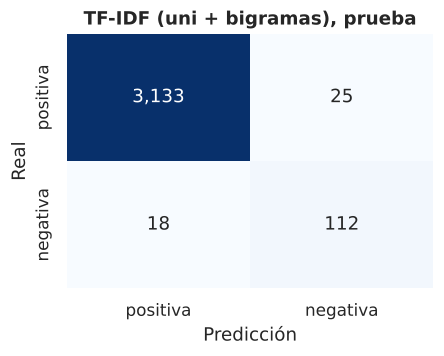

De 130 negativas reales se detectan 112; de 137 alarmas, 25 son reseñas positivas.


In [22]:
MEJOR = MODELOS['TF-IDF (uni + bigramas)']
p_te = MEJOR.predict_proba(A.loc[te_A, 'texto_modelo'])[:, 1]
pred_te = (p_te >= 0.5).astype(int)
cm = confusion_matrix(y_te, pred_te)
fig, ax = plt.subplots(figsize=(4.2, 3.4))
sns.heatmap(cm, annot=True, fmt=',', cmap='Blues', cbar=False, ax=ax,
            xticklabels=['positiva', 'negativa'], yticklabels=['positiva', 'negativa'])
ax.set_xlabel('Predicción'); ax.set_ylabel('Real'); ax.set_title('TF-IDF (uni + bigramas), prueba')
guardar_figura('06_matriz_confusion')
print(f'De {cm[1].sum()} negativas reales se detectan {cm[1, 1]}; de {cm[:, 1].sum()} alarmas, {cm[0, 1]} son reseñas positivas.')

Operativamente, si el hotel revisara solo las reseñas que el modelo marca como negativas, leería 137 en lugar de 3.288 (el 4,2 %) y encontraría 112 de las 130 quejas reales. La sección 8.3 analiza las 18 que se escapan.

## 4.5 Escenario C: ¿qué separa una estadía excelente de una buena?

Mismo modelo, ahora con 5★ frente a 1–4★ sobre todas las reseñas en inglés. La clase de interés ("no excelente") es el 24 % del corpus.

In [23]:
gs_C, pred_C = ajustar(vec_best(), datos=en, idx_tr=tr_C, idx_te=te_C, ycol='yC')
MODELO_C = gs_C.best_estimator_
y_te_C = en.loc[te_C, 'yC'].values
m_C = metricas(y_te_C, pred_C)
(fl, fh), (rl, rh) = ic_bootstrap(y_te_C, pred_C)
print(f"Escenario C | C={gs_C.best_params_['clf__C']} | F1-macro CV {gs_C.best_score_:.3f} | prueba: F1-macro {m_C['F1-macro']:.3f} "
      f"[{fl:.3f}, {fh:.3f}] | exactitud balanceada {m_C['Exactitud balanceada']:.3f} | "
      f"precisión 'no excelente' {m_C['Precisión neg.']:.3f} | recall 'no excelente' {m_C['Recall neg.']:.3f}")

Escenario C | C=4 | F1-macro CV 0.795 | prueba: F1-macro 0.806 [0.790, 0.823] | exactitud balanceada 0.814 | precisión 'no excelente' 0.686 | recall 'no excelente' 0.732


Separar una estadía excelente de una buena es más difícil que separar una buena de una mala: el F1-macro baja de 0,916 a 0,806. Es lo esperable, porque entre 4★ y 5★ la diferencia está en matices y no en quejas explícitas. La sección 5.5 muestra cuáles son esos matices.

# 5. Palabras que caracterizan una opinión negativa y una positiva

En una regresión logística, cada palabra o bigrama tiene un coeficiente. Si es positivo, su presencia **sube** la probabilidad de que la reseña sea negativa; si es negativo, la baja. Es la misma lectura de la sección 7 ("Interpretación del modelo") del taller de IMDB, con dos controles adicionales: la **estabilidad** de cada palabra entre particiones y el efecto de los **nombres propios**.

## 5.1 Coeficientes del mejor modelo

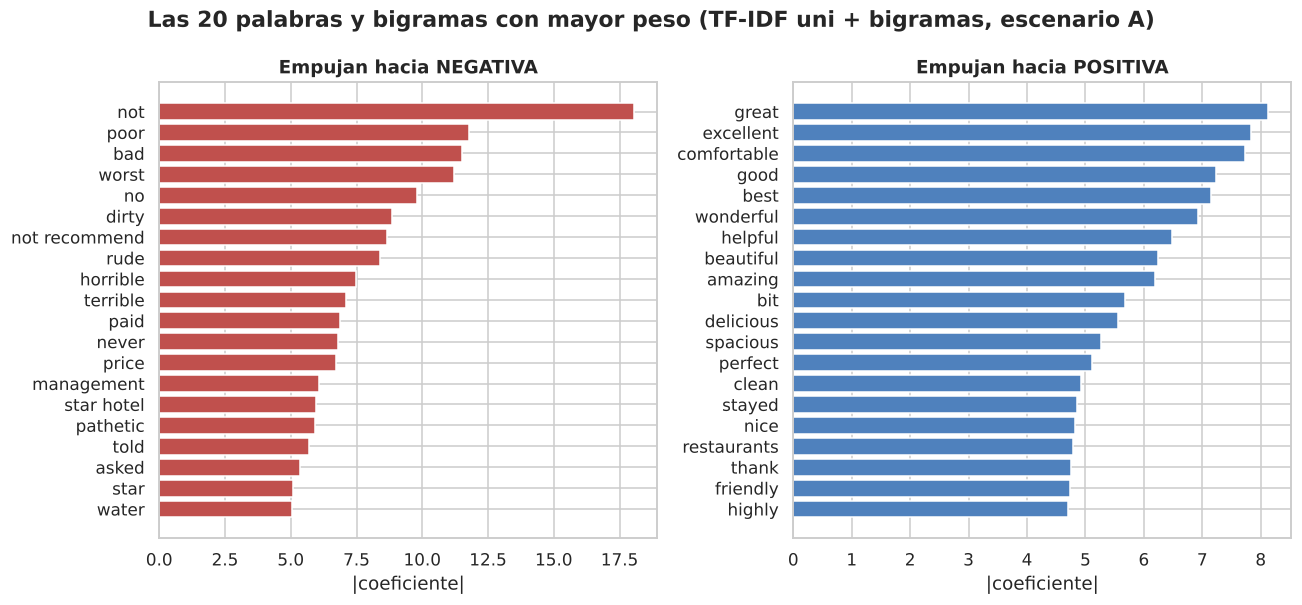

In [24]:
def coeficientes(modelo):
    return pd.Series(modelo['clf'].coef_[0], index=modelo['vec'].get_feature_names_out())

coef = coeficientes(MEJOR)
top_n, top_p = coef.nlargest(20), coef.nsmallest(20)
fig, axes = plt.subplots(1, 2, figsize=(12, 5.6))
axes[0].barh(top_n.index[::-1], top_n.values[::-1], color=COL['neg']); axes[0].set_title('Empujan hacia NEGATIVA')
axes[1].barh(top_p.index[::-1], -top_p.values[::-1], color=COL['pos']); axes[1].set_title('Empujan hacia POSITIVA')
for ax in axes:
    ax.set_xlabel('|coeficiente|')
plt.suptitle('Las 20 palabras y bigramas con mayor peso (TF-IDF uni + bigramas, escenario A)', fontweight='bold')
guardar_figura('07_palabras_negativas_positivas')

## 5.2 Estabilidad entre particiones

Una palabra que aparece en el top por azar de la partición no sirve para sacar conclusiones. Se reentrena el modelo en las 5 particiones de la validación cruzada y se cuenta en cuántas queda dentro del top 30 de su lado.

In [25]:
C_best = MEJOR['clf'].C
tops_n, tops_p = [], []
X_tr_txt = A.loc[tr_A, 'texto_modelo'].values
for a, b in CV5.split(X_tr_txt, y_tr):
    m = Pipeline([('vec', vec_best()), ('clf', LogisticRegression(C=C_best, class_weight='balanced', max_iter=5000))])
    m.fit(X_tr_txt[a], y_tr[a])
    c = coeficientes(m)
    tops_n.append(set(c.nlargest(30).index)); tops_p.append(set(c.nsmallest(30).index))

def tabla_estable(serie, tops):
    return pd.DataFrame({'coeficiente': serie.round(2), 'particiones (de 5)': [sum(w in t for t in tops) for w in serie.index]})

est_n = tabla_estable(coef.nlargest(30), tops_n)
est_p = tabla_estable(coef.nsmallest(30), tops_p)
print(f"Negativas: {(est_n['particiones (de 5)'] == 5).sum()} de 30 están en el top en las 5 particiones | "
      f"positivas: {(est_p['particiones (de 5)'] == 5).sum()} de 30")
display(pd.concat([est_n.reset_index().rename(columns={'index': 'hacia negativa'}),
                   est_p.reset_index().rename(columns={'index': 'hacia positiva'})], axis=1))

Negativas: 20 de 30 están en el top en las 5 particiones | positivas: 24 de 30


,hacia negativa,coeficiente,particiones (de 5),hacia positiva,coeficiente,particiones (de 5)
0,not,18.04,5,great,-8.12,5
1,poor,11.77,5,excellent,-7.84,5
2,bad,11.50,5,comfortable,-7.73,5
3,worst,11.21,5,good,-7.23,5
4,no,9.81,5,best,-7.15,5
5,dirty,8.87,5,wonderful,-6.93,5
6,not recommend,8.67,5,helpful,-6.48,5
7,rude,8.38,5,beautiful,-6.24,5
8,horrible,7.49,5,amazing,-6.18,5
9,terrible,7.08,5,bit,-5.67,5


**Las 20 palabras con más peso de cada lado están en el top 30 en las 5 particiones.** Son estables y se pueden interpretar. Las negativas forman cinco grupos:

| Grupo | Palabras (coeficiente) | Lectura |
|:--|:--|:--|
| Evaluación directa | poor (11,77), bad (11,50), worst (11,21), horrible (7,49), terrible (7,08), pathetic (5,92) | El juicio global |
| Negación | not (18,04), no (9,81), not recommend (8,67), never (6,79) | La negación es la señal individual más fuerte |
| Precio y categoría | paid (6,87), price (6,71), star hotel (5,98), star (5,10) | La brecha entre lo que se paga y lo que se recibe |
| Gestión de la queja | management (6,06), told (5,68), asked (5,34) | La reseña narra una solicitud y la respuesta |
| Fallas concretas | dirty (8,87), rude (8,38), water (5,05) | Limpieza, trato y servicios básicos |

Del lado positivo dominan los elogios (*great, excellent, best, wonderful, amazing*), la comodidad y el espacio (*comfortable, spacious, clean*), las personas (*helpful, friendly, thank*) y la comida (*delicious*). Un caso curioso es *bit* (−5,67): las reseñas positivas matizan sus críticas ("a bit small", "a bit noisy"), mientras que las negativas no matizan.

## 5.3 ¿El modelo aprende sentimiento o aprende hoteles?

Se compara el top 80 (40 por lado) del modelo entrenado **con** nombres propios frente al modelo con nombres enmascarados.

In [26]:
coef_np = coeficientes(MODELOS['TF-IDF (uni + bigramas) con nombres propios'])
top80_np = pd.concat([coef_np.nlargest(40), coef_np.nsmallest(40)])
con_nombre = [(w, round(v, 2)) for w, v in top80_np.items() if any(t in NP_SET for t in w.split())]
print('Nombres propios en el top 80 del modelo SIN enmascarar:', con_nombre)
top80 = pd.concat([coef.nlargest(40), coef.nsmallest(40)])
print('Nombres propios en el top 80 del modelo enmascarado:', [w for w in top80.index if any(t in NP_SET for t in w.split())])

Nombres propios en el top 80 del modelo SIN enmascarar: [('radisson', 5.28), ('nepal', -4.77), ('kathmandu', -4.7)]
Nombres propios en el top 80 del modelo enmascarado: []


Sin enmascarar, el modelo usaba *radisson* como palabra negativa (5,28) y *nepal* (−4,77) y *kathmandu* (−4,70) como palabras positivas. Eso no describe el servicio: describe qué hoteles y qué ciudades concentran las reseñas buenas o malas, y no generaliza a otro hotel. Con el enmascarado desaparecen del top 80, sin pérdida de desempeño (4.3).

## 5.4 Las palabras en contexto

Un coeficiente dice *que* una palabra pesa, no *por qué*. Para las palabras más reveladoras se mide en qué proporción de reseñas negativas y positivas aparecen, y se leen ejemplos.

In [27]:
TERMINOS = ['star hotel', 'price', 'paid', 'told', 'asked', 'management', 'water', 'not recommend']
neg_txt = A.loc[A['y'] == 1, 'texto_modelo']
pos_txt = A.loc[A['y'] == 0, 'texto_modelo']
filas = []
for t in TERMINOS:
    pat = re.compile(r'\b' + re.escape(t) + r'\b')
    pn, pp = neg_txt.str.contains(pat).mean(), pos_txt.str.contains(pat).mean()
    filas.append({'término': t, '% reseñas negativas': round(100 * pn, 1), '% reseñas positivas': round(100 * pp, 1),
                  'veces más frecuente en negativas': round(pn / pp, 1) if pp > 0 else np.inf,
                  'coeficiente': round(coef.get(t, np.nan), 2)})
display(pd.DataFrame(filas).set_index('término'))

def contexto(termino_original, n=2, ancho=110, seed=RANDOM_STATE):
    pat = re.compile(r'\b' + termino_original + r'\b', re.I)
    sub = A.loc[(A['y'] == 1) & A['Review'].str.contains(pat)].sample(frac=1, random_state=seed).head(n)
    for t in sub['Review']:
        m = pat.search(t)
        i = m.start()
        print(f"   …{t[max(0, i - ancho):i + ancho].strip()}…")

for termino in [r'star hotel', r'told', r'management', r'paid']:
    print(f'\n«{termino}» en reseñas negativas:')
    contexto(termino)

,% reseñas negativas,% reseñas positivas,veces más frecuente en negativas,coeficiente
término,,,,
star hotel,11.4,1.1,9.9,5.98
price,12.3,2.4,5.1,6.71
paid,9.1,0.7,12.7,6.87
told,14.3,1.1,13.6,5.68
asked,16.9,1.5,11.0,5.34
management,10.3,2.4,4.3,6.06
water,17.8,4.1,4.4,5.05
not recommend,8.2,0.4,20.4,8.67



«star hotel» en reseñas negativas:


   …physical standards of the property. Also staff should be trained in order to reach the service quality of a 5 star hotel.…
   …This has to be without doubt my worst ever hotel stay. It is classed as a 5 star hotel but that is a complete misrepresentation. My deluxe room was outdated and dingy. I went to the bar…

«told» en reseñas negativas:
   …eck my room and call me back. About 10 minutes later I called again and this time the person at the reception told me that they did not find my laptop in my room. Since the boarding has already started, I told the person…
   …be better if you book the restaurant directly on your own."Seriously?! I cannot believe that the "colleague" told not to help book my dinner reservation request... This is a five star property!I then sent this email cha…

«management» en reseñas negativas:


   …able. The worst Crowne Plaza you will ever stay in! The words Customer Service are non-existent to the entire management.Also, do not go up to the Concierge and ask for any recommendations as they will only send you to p…
   …front desk, they were very engaged, took notes while being apologetic and promising to take the issue up with management. All in all, the place is great but they must really address the restaurant aspect as it is otherwi…

«paid» en reseñas negativas:


   …& never going to recommend to anyone to visit this place !! If this hotel is having good ratings than must be paid for it or asked friends to provide awesome ratings .Please read carefully my feedback and if you are plan…
   …ing cash upfront would mean we get a special reduced rate. Realised that online the price was half of what we paid. Asked for hotel to refund us what we overpaid and they simply said no. I hate them all. Everyone has tol…


Leídas en contexto, las palabras cuentan tres historias que van más allá de "la reseña es mala":

1. **La queja es contra la promesa de la categoría.** *star hotel* aparece en el 11,4 % de las negativas y en el 1,1 % de las positivas (9,9 veces más). El huésped no dice solo "el cuarto estaba viejo", dice "para ser un 5 estrellas…". En un hotel de lujo, la vara de medir es la categoría.
2. **La queja nace en la respuesta, no en el problema.** *told* (13,6 veces más frecuente en negativas) y *asked* (11,0 veces) describen interacciones: el huésped pidió algo y la respuesta fue mala. El ejemplo del portátil perdido lo ilustra: el problema inicial se vuelve reseña negativa por cómo se manejó.
3. **El precio pesa como percepción de valor.** *paid* es 12,7 veces más frecuente en las negativas. En uno de los ejemplos, la tarifa en línea era la mitad de lo que pagó el huésped, y el hotel no le devolvió la diferencia. La sección 9.6 confirma el patrón a nivel de frase: el precio es el aspecto con mayor proporción de frases negativas.

La implicación operativa es concreta: un protocolo de respuesta a solicitudes y reclamos y la transparencia en tarifas e impuestos atacan las causas que más se repiten en las quejas.

## 5.5 Escenario C: las palabras de la excelencia

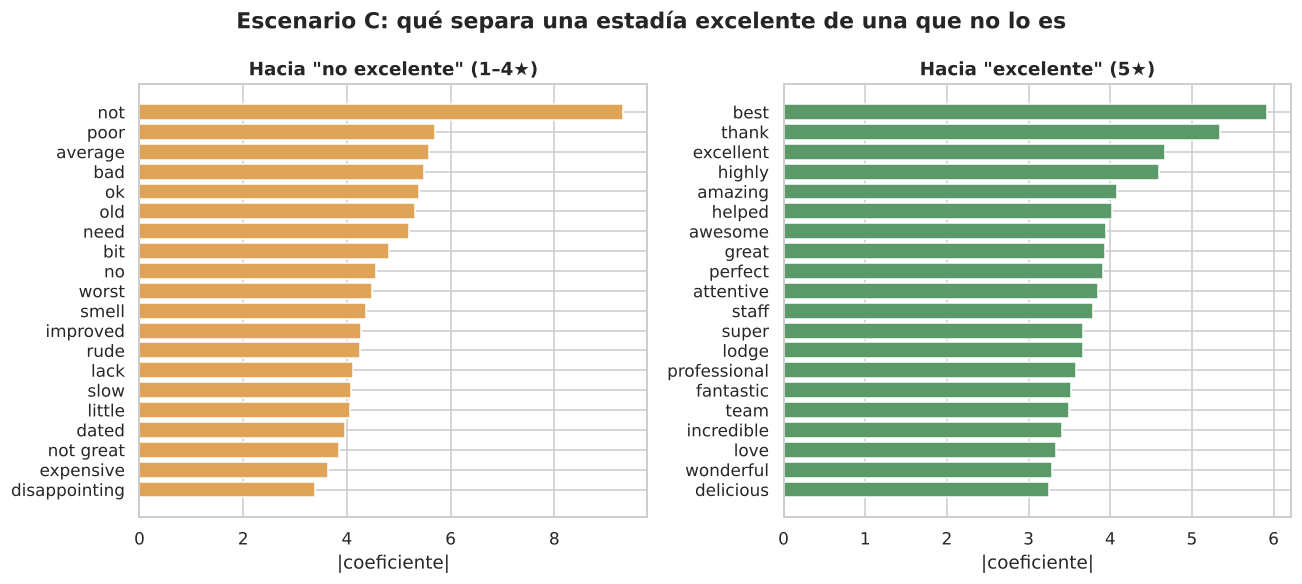

% de reseñas que mencionan staff / team / helped / thank(s), por calificación: {1: 46.9, 2: 50.5, 3: 47.3, 4: 55.7, 5: 69.3}


In [28]:
coef_C = coeficientes(MODELO_C)
cN, cE = coef_C.nlargest(20), coef_C.nsmallest(20)
fig, axes = plt.subplots(1, 2, figsize=(12, 5.4))
axes[0].barh(cN.index[::-1], cN.values[::-1], color='#e0a458'); axes[0].set_title('Hacia "no excelente" (1–4★)')
axes[1].barh(cE.index[::-1], -cE.values[::-1], color='#5b9a68'); axes[1].set_title('Hacia "excelente" (5★)')
for ax in axes:
    ax.set_xlabel('|coeficiente|')
plt.suptitle('Escenario C: qué separa una estadía excelente de una que no lo es', fontweight='bold')
guardar_figura('08_palabras_excelencia_escenario_C')

# ¿Cuánto se menciona al personal en cada calificación?
pat_staff = re.compile(r'\b(staff|team|helped|thank|thanks)\b')
print('% de reseñas que mencionan staff / team / helped / thank(s), por calificación:',
      (100 * en.groupby('Rating')['texto_modelo'].apply(lambda s: s.str.contains(pat_staff).mean())).round(1).to_dict())

**Qué le falta a una estadía de 4★ para ser de 5★.** Del lado "no excelente" aparecen palabras de conformidad (*average, ok, need, improved, bit, little*) y de instalaciones envejecidas (*old, dated, smell*). Del lado "excelente" aparecen la gratitud y las personas: *thank, helped, attentive, staff, professional, team*. El 69,3 % de las reseñas de 5★ menciona al personal o da las gracias, frente al 55,7 % de las de 4★ y entre el 46,9 % y el 50,5 % de las de 1–3★.

*bit* cambia de lado entre escenarios. En el escenario A empuja hacia "positiva" y en el C hacia "no excelente": una crítica menor no vuelve negativa una reseña, pero le impide ser excelente. Para la gerencia, el paso de 4★ a 5★ depende del trato personal que el huésped reconoce, y lo que lo frena es el mantenimiento de las instalaciones.

# 6. Word2Vec del dominio hotelero

## 6.1 Entrenamiento

Se entrena un skip-gram con muestreo negativo, como en el taller de Word2Vec. Hay tres decisiones de diseño:

- **Sin fuga de información:** el corpus son todas las reseñas en inglés **excepto las de prueba del escenario A** (incluye las de 3★, que no están en ninguna prueba). Así, la comparación con TF-IDF de la sección 6.4 es justa.
- **Texto con stop words** (`tok_w2v`): la ventana de contexto necesita las palabras reales que rodean a cada término.
- **Un solo hilo** (`workers=1`) y semilla fija: con varios hilos, Word2Vec no es reproducible.

In [29]:
idx_w2v = en.index.difference(te_A)
corpus_w2v = en.loc[idx_w2v, 'tok_w2v'].tolist()
W2V_PARAMS = dict(vector_size=100, window=5, min_count=5, sg=1, negative=10, epochs=10, seed=RANDOM_STATE)
f_w2v = CACHE / 'w2v_hoteles.model'
t0 = time.time()
if f_w2v.exists():
    w2v = Word2Vec.load(str(f_w2v))
else:
    w2v = Word2Vec(corpus_w2v, workers=1, **W2V_PARAMS)
    w2v.save(str(f_w2v))
V = w2v.wv
print(f'Reseñas: {len(corpus_w2v):,} | tokens: {sum(map(len, corpus_w2v)):,} | vocabulario (min_count=5): {len(V):,} | '
      f'{time.time() - t0:.0f} s')

Reseñas: 13,974 | tokens: 1,265,386 | vocabulario (min_count=5): 7,244 | 0 s


## 6.2 Efecto del tamaño de la ventana

La ventana define qué se considera "contexto". Una ventana corta tiende a capturar similitud funcional (palabras intercambiables); una larga, relación temática (palabras del mismo tema).

In [30]:
ODD = [['breakfast', 'lunch', 'dinner', 'buffet', 'towel'], ['pool', 'spa', 'gym', 'sauna', 'omelette'],
       ['shower', 'bathtub', 'toilet', 'sink', 'receptionist'], ['dirty', 'filthy', 'smelly', 'stained', 'spacious'],
       ['wifi', 'internet', 'connection', 'pillow'], ['taxi', 'airport', 'pickup', 'transfer', 'curry'],
       ['coffee', 'tea', 'juice', 'wine', 'bed'], ['noise', 'noisy', 'loud', 'traffic', 'delicious'],
       ['rude', 'unprofessional', 'arrogant', 'helpful'], ['manager', 'receptionist', 'waiter', 'doorman', 'mattress']]

def odd_one_out(kv):
    return [(s[-1], kv.doesnt_match(s)) for s in ODD]

ventanas = {5: w2v}
for win in [2, 10]:
    f = CACHE / f'w2v_ventana{win}.model'
    if f.exists():
        ventanas[win] = Word2Vec.load(str(f))
    else:
        ventanas[win] = Word2Vec(corpus_w2v, workers=1, **(W2V_PARAMS | {'window': win}))
        ventanas[win].save(str(f))

filas = []
for win in [2, 5, 10]:
    kv = ventanas[win].wv
    fila = {'ventana': win, 'término discordante (aciertos de 10)': sum(a == b for a, b in odd_one_out(kv))}
    for w in ['staff', 'pool', 'breakfast']:
        fila[f'vecinos de "{w}"'] = ', '.join(n for n, _ in kv.most_similar(w, topn=6))
    filas.append(fila)
display(pd.DataFrame(filas).set_index('ventana'))

,término discordante (aciertos de 10),"vecinos de ""staff""","vecinos de ""pool""","vecinos de ""breakfast"""
ventana,,,,
2,10,"staffs, employees, personnel, staf, crew, waitstaff","pools, jacuzzi, swimming, poll, whirlpool, indoor","comprehensive, bf, breakfasts, buffet, ala, bfast"
5,10,"staffs, personnel, employees, exceedingly, chatty, graceful","swimming, pools, indoor, jacuzzi, whirlpool, unheated","buffet, comprehensive, ala, hygenic, specials, breakfasts"
10,10,"staffs, waitstaff, personnel, professional, polite, chatty","swimming, jacuzzi, pools, indoor, sunbeds, unheated","buffet, ala, food, omlette, choices, comprehensive"


Las tres ventanas aciertan 10 de 10 en la prueba del término discordante, así que la diferencia está en el tipo de vecino. Con **ventana 2** aparecen variantes y sinónimos intercambiables: *staf, crew* para staff y *bf, bfast* para breakfast. Con **ventana 10** aparecen palabras del mismo tema que describen al término: *professional, polite* para staff y *sunbeds, unheated* para pool. Se usa ventana 5, un punto intermedio.

## 6.3 Evaluación intrínseca

In [31]:
PALABRAS_ASPECTO = ['staff', 'breakfast', 'pool', 'wifi', 'spa', 'dirty', 'rude', 'noisy', 'expensive']
display(pd.DataFrame({w: [f'{n} ({s:.2f})' for n, s in V.most_similar(w, topn=6)] for w in PALABRAS_ASPECTO},
                     index=[f'vecino {i}' for i in range(1, 7)]).T)

res_odd = odd_one_out(w2v.wv)
print('Término discordante:', sum(a == b for a, b in res_odd), 'de', len(res_odd), 'aciertos')
for s, (esperado, obtenido) in zip(ODD, res_odd):
    print(f"   {', '.join(s):48s} -> {obtenido:12s} {'✓' if esperado == obtenido else '✗ (esperado ' + esperado + ')'}")

print('\nAnalogías (a : b :: c : ?), top 3:')
for a, b, c in [('breakfast', 'morning', 'dinner'), ('pool', 'swim', 'restaurant'),
                ('room', 'spacious', 'staff'), ('kathmandu', 'nepal', 'delhi')]:
    try:
        r = V.most_similar(positive=[b, c], negative=[a], topn=3)
        print(f"   {a} : {b} :: {c} : ? -> {', '.join(f'{w} ({s:.2f})' for w, s in r)}")
    except KeyError as e:
        print(f'   {a} : {b} :: {c} : ? -> palabra fuera del vocabulario ({e})')

,vecino 1,vecino 2,vecino 3,vecino 4,vecino 5,vecino 6
staff,staffs (0.81),personnel (0.77),employees (0.76),exceedingly (0.72),chatty (0.70),graceful (0.70)
breakfast,buffet (0.74),comprehensive (0.71),ala (0.68),hygenic (0.67),specials (0.67),breakfasts (0.66)
pool,swimming (0.78),pools (0.72),indoor (0.72),jacuzzi (0.72),whirlpool (0.70),unheated (0.69)
wifi,fi (0.83),wi (0.81),internet (0.80),connectivity (0.72),chargeable (0.71),wireless (0.70)
spa,sauna (0.74),gym (0.73),steam (0.73),massages (0.72),massage (0.72),facials (0.71)
dirty,moldy (0.79),filthy (0.79),smelly (0.77),carpet (0.76),carpets (0.75),damp (0.74)
rude,unprofessional (0.75),unfriendly (0.67),untrained (0.66),arrogant (0.66),angry (0.66),corrected (0.65)
noisy,crowded (0.74),overcrowded (0.72),polluted (0.71),busy (0.69),dusty (0.68),loud (0.68)
expensive,pricey (0.80),pricy (0.74),price (0.70),overpriced (0.68),ridiculously (0.66),costly (0.66)


Término discordante: 10 de 10 aciertos
   breakfast, lunch, dinner, buffet, towel          -> towel        ✓
   pool, spa, gym, sauna, omelette                  -> omelette     ✓
   shower, bathtub, toilet, sink, receptionist      -> receptionist ✓
   dirty, filthy, smelly, stained, spacious         -> spacious     ✓
   wifi, internet, connection, pillow               -> pillow       ✓
   taxi, airport, pickup, transfer, curry           -> curry        ✓
   coffee, tea, juice, wine, bed                    -> bed          ✓
   noise, noisy, loud, traffic, delicious           -> delicious    ✓
   rude, unprofessional, arrogant, helpful          -> helpful      ✓
   manager, receptionist, waiter, doorman, mattress -> mattress     ✓

Analogías (a : b :: c : ?), top 3:
   breakfast : morning :: dinner : ? -> afternoon (0.64), evening (0.57), sundowner (0.56)
   pool : swim :: restaurant : ? -> diner (0.52), caf (0.52), dinner (0.49)
   room : spacious :: staff : ? -> delightfully (0.62), em

- **Los vecinos tienen sentido de dominio.** *pool* → *swimming, jacuzzi, whirlpool, unheated*; *wifi* → *internet, connectivity, chargeable* (el wifi con cobro, que vuelve a aparecer en 9.6); *rude* → *unprofessional, unfriendly, untrained, arrogant*. También aparecen las limitaciones conocidas de la semántica distribucional: *dirty* → *carpet* es una asociación, no un sinónimo, y *noisy* → *crowded, polluted, dusty* describe la ciudad, no el hotel.
- **Término discordante:** 10 de 10. Incluso separa *helpful* de *rude, unprofessional, arrogant*, aunque los antónimos suelen compartir contextos.
- **Analogías:** solo *breakfast : morning :: dinner : ?* se acerca a lo esperado (*evening* en el segundo lugar); las otras tres fallan (*delhi* lleva a *australia*, no a *india*). Es lo que advierte la presentación del curso: el método del paralelogramo solo funciona para palabras frecuentes y relaciones acotadas. Con 1,27 millones de tokens, este corpus es muy pequeño para eso.

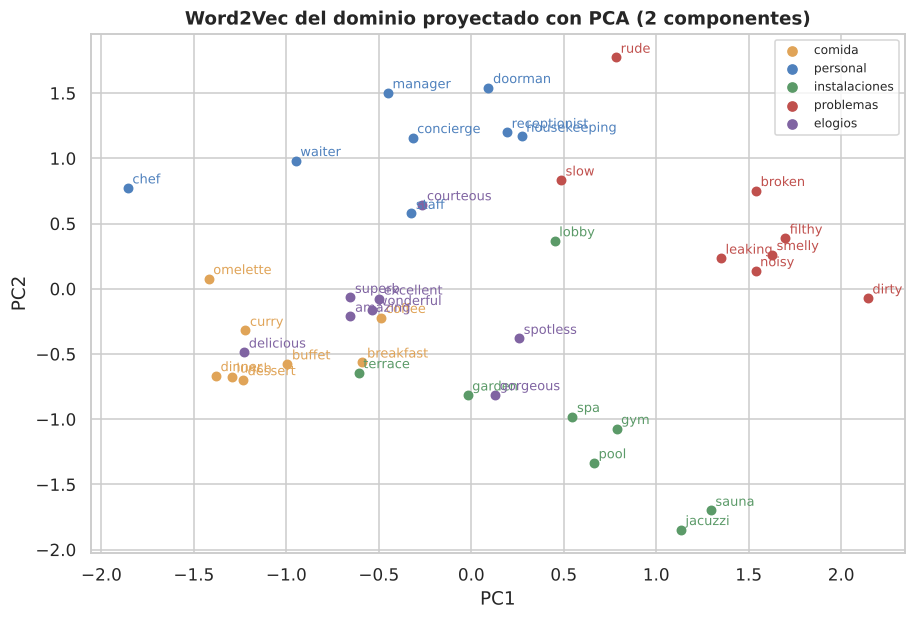

In [32]:
GRUPOS = {'comida': ['breakfast', 'buffet', 'dinner', 'lunch', 'coffee', 'curry', 'omelette', 'dessert'],
          'personal': ['staff', 'receptionist', 'waiter', 'manager', 'doorman', 'concierge', 'housekeeping', 'chef'],
          'instalaciones': ['pool', 'spa', 'gym', 'sauna', 'lobby', 'garden', 'jacuzzi', 'terrace'],
          'problemas': ['dirty', 'noisy', 'rude', 'smelly', 'broken', 'slow', 'filthy', 'leaking'],
          'elogios': ['excellent', 'wonderful', 'amazing', 'delicious', 'spotless', 'superb', 'gorgeous', 'courteous']}
palabras = [w for g in GRUPOS.values() for w in g if w in V]
xy = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(np.array([V[w] for w in palabras]))
colores = dict(zip(GRUPOS, ['#e0a458', '#4f81bd', '#5b9a68', '#c0504d', '#8064a2']))
fig, ax = plt.subplots(figsize=(8.5, 5.8))
for (x, y_), w in zip(xy, palabras):
    g = next(k for k, v in GRUPOS.items() if w in v)
    ax.scatter(x, y_, color=colores[g], s=30)
    ax.annotate(w, (x, y_), fontsize=8.5, xytext=(3, 3), textcoords='offset points', color=colores[g])
for g, c in colores.items():
    ax.scatter([], [], color=c, label=g)
ax.legend(loc='best', fontsize=8); ax.set_title('Word2Vec del dominio proyectado con PCA (2 componentes)')
ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
guardar_figura('09_word2vec_pca')

Aun reducidos a dos dimensiones, los grupos se separan. El personal queda arriba, los problemas a la derecha, las instalaciones abajo y la comida a la izquierda. Los elogios quedan en el centro, cerca de la comida y del personal, que son lo que más se elogia. *rude* queda a la vez cerca de los problemas y del personal, porque un trato grosero es un problema *del* personal. Como advirtió el taller, PCA conserva solo una parte de la varianza: la cercanía en el gráfico es orientativa, y las distancias que cuentan son las de las 100 dimensiones.

## 6.4 Clasificación con vectores de documento

Cada reseña se representa con el **promedio** de los vectores de sus palabras de contenido, o con el **promedio ponderado por IDF**, que le da más peso a las palabras raras. Igual que en el clasificador, se excluyen las stop words y los nombres propios.

In [33]:
SW_W2V = CUSTOM_STOP_WORDS | NP_SET

def vec_promedio(tokens):
    vs = [V[w] for w in tokens if w in V.key_to_index and w not in SW_W2V]
    return np.mean(vs, axis=0) if vs else np.zeros(V.vector_size, dtype=np.float32)

tfidf_w = TfidfVectorizer(min_df=3, token_pattern=r'[a-z]+').fit(A.loc[tr_A, 'tok_w2v'].apply(' '.join))
IDF = dict(zip(tfidf_w.get_feature_names_out(), tfidf_w.idf_))

def vec_ponderado(tokens):
    ws = [w for w in tokens if w in V.key_to_index and w in IDF and w not in SW_W2V]
    if not ws:
        return np.zeros(V.vector_size, dtype=np.float32)
    pesos = np.array([IDF[w] for w in ws])
    return (np.array([V[w] for w in ws]) * pesos[:, None]).sum(0) / pesos.sum()

X_avg = np.vstack(A['tok_w2v'].apply(vec_promedio))
X_pond = np.vstack(A['tok_w2v'].apply(vec_ponderado))
i_tr, i_te = A.index.get_indexer(tr_A), A.index.get_indexer(te_A)
C_W2V = {}
for nombre, X in [('Word2Vec promedio', X_avg), ('Word2Vec ponderado por IDF', X_pond)]:
    gs = GridSearchCV(LogisticRegression(class_weight='balanced', max_iter=5000), {'C': [1, 4, 16, 64]},
                      scoring='f1_macro', cv=CV5, n_jobs=-1).fit(X[i_tr], y_tr)
    C_W2V[nombre] = gs.best_params_['C']
    registrar(nombre, y_te, gs.predict(X[i_te]), cv=gs.best_score_, C=gs.best_params_['C'])
tabla_resultados()

,C,F1-macro CV,F1-macro,Exactitud balanceada,Precisión neg.,Recall neg.,Exactitud,IC95 F1-macro,IC95 recall neg.
Modelo,,,,,,,,,
Línea base: siempre positiva,—,—,0.490,0.500,0.000,0.000,0.960,"[0.488, 0.492]","[0.000, 0.000]"
Línea base: solo longitud,—,—,0.456,0.574,0.058,0.454,0.685,"[0.441, 0.470]","[0.365, 0.544]"
Binaria (unigramas),16,0.896,0.885,0.877,0.798,0.762,0.983,"[0.854, 0.914]","[0.686, 0.837]"
BoW (unigramas),1,0.882,0.903,0.918,0.786,0.846,0.985,"[0.876, 0.929]","[0.781, 0.907]"
TF-IDF (unigramas),64,0.903,0.913,0.919,0.821,0.846,0.987,"[0.887, 0.935]","[0.788, 0.906]"
TF-IDF (uni + bigramas),16,0.912,0.916,0.927,0.818,0.862,0.987,"[0.890, 0.939]","[0.800, 0.919]"
TF-IDF (uni + bigramas) + lematización,64,0.909,0.913,0.919,0.821,0.846,0.987,"[0.887, 0.938]","[0.780, 0.904]"
TF-IDF (uni + bigramas) con nombres propios,64,0.913,0.910,0.912,0.824,0.831,0.986,"[0.884, 0.934]","[0.766, 0.895]"
Word2Vec promedio,64,0.806,0.813,0.949,0.494,0.938,0.960,"[0.784, 0.840]","[0.893, 0.978]"


Con todos los datos, Word2Vec queda por debajo de TF-IDF: 0,813 con el promedio y 0,805 con la ponderación por IDF, frente a 0,916. El patrón de error es distinto: detecta el 93,8 % de las negativas, pero con una precisión de 0,494, es decir, la mitad de sus alarmas son falsas. Al promediar, una palabra decisiva como *worst* o *rude* queda diluida entre decenas de palabras neutras, y el vector se parece al de cualquier reseña crítica. TF-IDF conserva esas palabras como dimensiones separadas.

## 6.5 Curva de aprendizaje: ¿cuándo conviene Word2Vec?

La hipótesis del anteproyecto era que TF-IDF ganaría con todos los datos, y que Word2Vec sería competitivo con pocos ejemplos etiquetados. Se entrena el clasificador con subconjuntos estratificados de la partición de entrenamiento (3 repeticiones por tamaño) y se evalúa siempre en la misma prueba. Word2Vec ya fue entrenado **sin etiquetas** con todo el texto de entrenamiento; solo el clasificador ve las `n` etiquetas.

,negativas en entrenamiento,TF-IDF (uni + bigramas),Word2Vec promedio,Word2Vec ponderado por IDF
n,,,,
250,10.0,0.587,0.831,0.816
500,20.0,0.717,0.830,0.822
1000,40.0,0.804,0.832,0.826
2000,79.0,0.855,0.828,0.817
4000,158.0,0.887,0.842,0.833
8000,316.0,0.900,0.828,0.814
13149,520.0,0.916,0.813,0.805


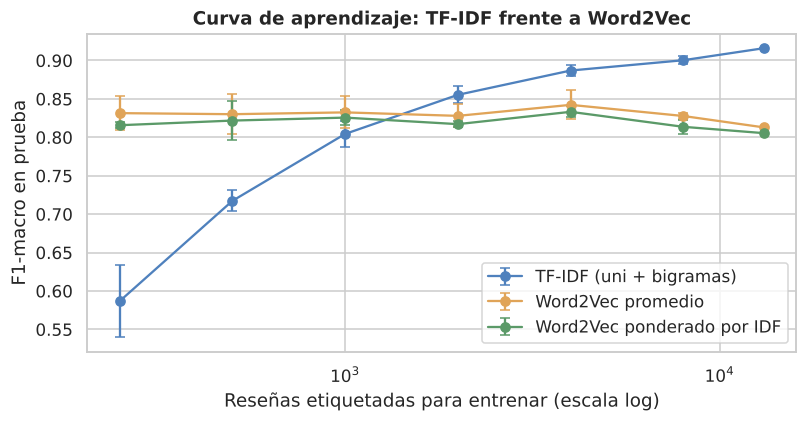

In [34]:
TAMANOS = [250, 500, 1000, 2000, 4000, 8000, len(i_tr)]
filas = []
for n in TAMANOS:
    for rep in (range(3) if n < len(i_tr) else [0]):
        sub = i_tr if n == len(i_tr) else train_test_split(i_tr, train_size=n, stratify=y_tr, random_state=rep)[0]
        ys = A['y'].values[sub]
        m_t = Pipeline([('vec', vec_best()), ('clf', LogisticRegression(C=C_best, class_weight='balanced', max_iter=5000))])
        m_t.fit(A['texto_modelo'].values[sub], ys)
        f_t = f1_score(y_te, m_t.predict(A.loc[te_A, 'texto_modelo']), average='macro')
        f_a = f1_score(y_te, LogisticRegression(C=C_W2V['Word2Vec promedio'], class_weight='balanced', max_iter=5000)
                       .fit(X_avg[sub], ys).predict(X_avg[i_te]), average='macro')
        f_p = f1_score(y_te, LogisticRegression(C=C_W2V['Word2Vec ponderado por IDF'], class_weight='balanced', max_iter=5000)
                       .fit(X_pond[sub], ys).predict(X_pond[i_te]), average='macro')
        filas.append({'n': n, 'negativas en entrenamiento': int(ys.sum()), 'TF-IDF (uni + bigramas)': f_t,
                      'Word2Vec promedio': f_a, 'Word2Vec ponderado por IDF': f_p})
curva = pd.DataFrame(filas)
resumen_curva = curva.groupby('n').mean().round(3)
display(resumen_curva)

fig, ax = plt.subplots(figsize=(7.5, 4))
for col, c in [('TF-IDF (uni + bigramas)', COL['pos']), ('Word2Vec promedio', '#e0a458'), ('Word2Vec ponderado por IDF', '#5b9a68')]:
    g = curva.groupby('n')[col]
    ax.errorbar(g.mean().index, g.mean().values, yerr=g.std().fillna(0).values, marker='o', capsize=3, label=col, color=c)
ax.set_xscale('log'); ax.set_xlabel('Reseñas etiquetadas para entrenar (escala log)'); ax.set_ylabel('F1-macro en prueba')
ax.set_title('Curva de aprendizaje: TF-IDF frente a Word2Vec'); ax.legend()
guardar_figura('10_curva_aprendizaje')

**Se confirma la hipótesis del anteproyecto.** Con 250 reseñas etiquetadas (10 negativas), Word2Vec promedio logra 0,831 y TF-IDF 0,587. Las curvas se cruzan entre 1.000 etiquetas (0,804 frente a 0,832) y 2.000 (0,855 frente a 0,828). Con todo el entrenamiento, TF-IDF llega a 0,916 y Word2Vec se queda en 0,813.

Word2Vec aprendió el significado de las palabras con texto **sin etiquetar**, y por eso necesita muy pocas etiquetas para empezar. TF-IDF tiene que descubrir cada palabra negativa a partir de ejemplos etiquetados. En la práctica: para un hotel o una cadena nueva con pocas reseñas calificadas, conviene empezar con embeddings y pasar a TF-IDF cuando haya unas 2.000 reseñas etiquetadas.

# 7. Proyecciones semánticas

Como en el taller de proyecciones, una **dirección semántica** se construye restando vectores: aquí, el promedio de varias palabras ancla de un polo menos el del otro. Proyectar una palabra sobre esa dirección da un puntaje: positivo si se parece al primer polo, negativo si se parece al segundo. Se usan varias anclas por polo, no una sola: el taller mostró que una dirección de un solo par (*king − queen*) puede capturar otra cosa (género en lugar de realeza).

## 7.1 ¿Qué ejes tienen señal en este corpus?

In [35]:
CANDIDATOS = {
    'personal': (['friendly', 'courteous', 'helpful', 'attentive', 'polite'], ['rude', 'unprofessional', 'arrogant', 'unfriendly', 'surly']),
    'limpieza': (['clean', 'spotless', 'tidy', 'hygienic', 'immaculate'], ['dirty', 'filthy', 'smelly', 'stained', 'dusty']),
    'comida': (['delicious', 'tasty', 'flavorful', 'yummy'], ['bland', 'tasteless', 'inedible', 'stale']),
    'precio': (['affordable', 'reasonable', 'worth', 'value'], ['overpriced', 'expensive', 'pricey', 'cheap'])}
tok_sets = en['tok_w2v'].apply(set)
filas = []
for eje, (pos, neg) in CANDIDATOS.items():
    for polo, ws in [('+', pos), ('−', neg)]:
        for w in ws:
            filas.append({'eje': eje, 'polo': polo, 'ancla': w, '% reseñas': round(100 * tok_sets.apply(lambda s: w in s).mean(), 2),
                          'en vocabulario': w in V.key_to_index})
anclas = pd.DataFrame(filas)
display(anclas.pivot_table(index=['eje', 'polo'], values='% reseñas', aggfunc=['min', 'median', 'max']).round(2))
print('Anclas fuera del vocabulario de Word2Vec:', anclas.loc[~anclas['en vocabulario'], 'ancla'].tolist())

min    median       max
              % reseñas % reseñas % reseñas
eje      polo                              
comida   +         0.06      1.86      9.63
         −         0.02      0.07      0.14
limpieza +         0.28      0.55     16.63
         −         0.13      0.15      0.82
personal +         3.97      5.88     21.72
         −         0.03      0.08      0.49
precio   +         0.34      1.64      4.38
         −         0.38      0.48      2.24

Anclas fuera del vocabulario de Word2Vec: ['inedible']


El polo negativo de **comida** es el más débil: su ancla más frecuente aparece en el 0,14 % de las reseñas, y *inedible* ni siquiera entra al vocabulario. El polo negativo de **personal** también es raro (mediana de 0,08 %), pero *rude* aparece en el 0,49 % de las reseñas y la validación de 7.2 confirma que el eje funciona. **Precio** tiene anclas frecuentes (*expensive* aparece en el 2,24 %), pero ambiguas en un hotel de lujo: *cheap* suele ser una queja ("cheap furniture") y *expensive* no siempre lo es. Se conservan **personal** y **limpieza**.

## 7.2 Construcción y validación de los ejes

La validación usa palabras que **no** son anclas y cuyo polo se conoce de antemano. Si el eje captura el concepto, sus proyecciones deben separarlas (AUC cercana a 1).

In [36]:
def unit(v):
    return v / np.linalg.norm(v)

VALIDACION = {
    'personal': (['welcoming', 'warm', 'caring', 'professional', 'accommodating', 'smiling', 'generous', 'kind', 'hospitable', 'cheerful'],
                 ['ignored', 'lazy', 'indifferent', 'untrained', 'rudely', 'careless', 'disrespectful', 'incompetent', 'shouting', 'unhelpful']),
    'limpieza': (['neat', 'fresh', 'sparkling', 'pristine', 'maintained', 'sanitized', 'crisp', 'washed', 'cleaned', 'tidied'],
                 ['moldy', 'stains', 'cockroach', 'dust', 'hair', 'mold', 'cockroaches', 'stink', 'damp', 'grimy'])}
EJES, DIR = ['personal', 'limpieza'], {}
for eje in EJES:
    pos, neg = CANDIDATOS[eje]
    DIR[eje] = unit(np.mean([unit(V[w]) for w in pos if w in V], 0) - np.mean([unit(V[w]) for w in neg if w in V], 0))
    vp = [w for w in VALIDACION[eje][0] if w in V]
    vn = [w for w in VALIDACION[eje][1] if w in V]
    sc = [unit(V[w]) @ DIR[eje] for w in vp + vn]
    auc = roc_auc_score([1] * len(vp) + [0] * len(vn), sc)
    proy = pd.Series({w: unit(V[w]) @ DIR[eje] for w in V.index_to_key[:5000] if w not in set(pos + neg)})
    print(f'Eje {eje}: AUC de validación = {auc:.3f} ({len(vp)} + {len(vn)} palabras; fuera del vocabulario: '
          f'{[w for w in VALIDACION[eje][0] + VALIDACION[eje][1] if w not in V]})')
    print(f"   extremo +: {', '.join(proy.nlargest(10).index)}")
    print(f"   extremo −: {', '.join(proy.nsmallest(10).index)}")

Eje personal: AUC de validación = 1.000 (10 + 6 palabras; fuera del vocabulario: ['careless', 'disrespectful', 'incompetent', 'unhelpful'])
   extremo +: accommodating, hospitable, supportive, welcoming, wholesome, spotlessly, tasteful, specious, comfortable, pleasent
   extremo −: error, remove, pointed, trash, shocking, warning, report, discuss, videos, bothered
Eje limpieza: AUC de validación = 0.952 (9 + 7 palabras; fuera del vocabulario: ['tidied', 'cockroaches', 'stink', 'grimy'])
   extremo +: delicious, compliments, neat, outstanding, decorated, impeccable, mouthwatering, catered, superbly, supportive
   extremo −: cigarette, smoke, carpet, load, smelled, odor, musty, trash, dead, oil


Las dos AUC son altas (1,000 para personal y 0,952 para limpieza), pero los extremos del vocabulario muestran algo más. En el polo negativo de **personal** no aparecen conductas del personal, sino palabras de cualquier reclamo: *error, remove, trash, shocking, warning, report*. En el polo positivo de **limpieza** aparecen elogios generales: *delicious, compliments, outstanding, superbly*. Es la primera señal de que los ejes podrían estar midiendo sentimiento general (7.4).

## 7.3 Puntaje por reseña y relación con la calificación

Hay dos formas de puntuar una reseña. La primera usa **toda la reseña**: el promedio de las proyecciones de todas sus palabras de contenido. La segunda es una **ventana del aspecto**: solo las palabras a ±4 posiciones de una mención del aspecto ("staff", "reception"… para personal; "room", "bathroom"… para limpieza). En ambos casos se excluyen las anclas, para no medir el eje con las mismas palabras que lo definen.

In [37]:
ASPECTO_EJE = {'personal': ['staff', 'reception', 'receptionist', 'waiter', 'waiters', 'manager', 'service', 'employees'],
               'limpieza': ['room', 'rooms', 'bathroom', 'toilet', 'bed', 'sheets', 'carpet', 'towels', 'linen', 'shower']}

V_UNIT = V.get_normed_vectors()
PROY = {eje: dict(zip(V.index_to_key, V_UNIT @ DIR[eje])) for eje in EJES}   # proyección de cada palabra del vocabulario

def puntaje(tokens, eje, ventana=None):
    excl = set(CANDIDATOS[eje][0] + CANDIDATOS[eje][1]) | SW_W2V
    if ventana is None:
        ws = [w for w in tokens if w in PROY[eje] and w not in excl]
    else:
        pos_asp = [i for i, w in enumerate(tokens) if w in ASPECTO_EJE[eje]]
        ws = {tokens[j] for i in pos_asp for j in range(max(0, i - ventana), min(len(tokens), i + ventana + 1))}
        ws = [w for w in ws if w in PROY[eje] and w not in excl and w not in ASPECTO_EJE[eje]]
    return float(np.mean([PROY[eje][w] for w in ws])) if ws else np.nan

filas, medias = [], {}
for eje in EJES:
    en[f'proy_{eje}_resena'] = en['tok_w2v'].apply(lambda t: puntaje(t, eje))
    en[f'proy_{eje}_aspecto'] = en['tok_w2v'].apply(lambda t: puntaje(t, eje, ventana=4))
    for modo in ['resena', 'aspecto']:
        s = en[f'proy_{eje}_{modo}']
        ok = s.notna()
        filas.append({'eje': eje, 'puntaje': 'toda la reseña' if modo == 'resena' else 'ventana del aspecto',
                      'cobertura': f'{ok.mean():.1%}', 'Spearman con Rating': round(spearmanr(s[ok], en.loc[ok, 'Rating']).statistic, 3)})
        medias[(eje, modo)] = s.groupby(en['Rating']).mean()
display(pd.DataFrame(filas).set_index(['eje', 'puntaje']))
display(pd.DataFrame(medias).round(3).rename_axis('Rating'))
r_cruzada = spearmanr(en['proy_personal_resena'], en['proy_limpieza_resena'], nan_policy='omit').statistic
print(f'Correlación entre los dos ejes con toda la reseña: {r_cruzada:.3f}')

cobertura  Spearman con Rating
eje      puntaje                                           
personal toda la reseña         100.0%                0.445
         ventana del aspecto     74.7%                0.268
limpieza toda la reseña         100.0%                0.458
         ventana del aspecto     50.8%                0.429

personal         limpieza        
         resena aspecto   resena aspecto
Rating                                  
1        -0.095  -0.099   -0.012  -0.044
2        -0.082  -0.076   -0.007  -0.039
3        -0.046  -0.018    0.021   0.004
4         0.013   0.055    0.077   0.081
5         0.049   0.083    0.121   0.141

Correlación entre los dos ejes con toda la reseña: 0.904


Los dos puntajes crecen de forma monótona con la calificación. Con toda la reseña, la correlación de Spearman es de 0,445 (personal) y 0,458 (limpieza). En la ventana del aspecto es de 0,268 y 0,429, sobre el 74,7 % y el 50,8 % de las reseñas que mencionan el aspecto. Pero la correlación **entre los dos ejes** es de 0,904: si dos ejes que deberían medir cosas distintas casi coinciden, lo más probable es que midan lo mismo.

## 7.4 ¿Los ejes miden el aspecto o el sentimiento general?

La correlación de 0,90 entre los dos ejes, medida sobre toda la reseña, es una alerta: si "personal" y "limpieza" casi coinciden, es probable que ambos midan lo mismo, que la reseña es buena o mala. Es el mismo problema del taller de proyecciones, donde *king − queen* medía género y no realeza. La corrección también es la misma: se construye una dirección de **sentimiento general** S (*excellent, great… − terrible, horrible…*) y se le **resta** a cada eje su componente sobre S.

eje⊥ = (eje − (eje · S) S) / ‖eje − (eje · S) S‖

In [38]:
GENERALES_POS = ['excellent', 'great', 'wonderful', 'amazing', 'perfect', 'fantastic']
GENERALES_NEG = ['terrible', 'horrible', 'awful', 'worst', 'bad', 'pathetic']
S_DIR = unit(np.mean([unit(V[w]) for w in GENERALES_POS], 0) - np.mean([unit(V[w]) for w in GENERALES_NEG], 0))
PRUEBA_GENERAL = ['excellent', 'great', 'wonderful', 'amazing', 'perfect', 'terrible', 'horrible', 'awful', 'worst', 'bad',
                  'delicious', 'outstanding', 'disappointing', 'superb']
DIR_ORT, filas = {}, []
for eje in EJES:
    d = DIR[eje]
    DIR_ORT[eje] = unit(d - (d @ S_DIR) * S_DIR)
    vp = [w for w in VALIDACION[eje][0] if w in V]
    vn = [w for w in VALIDACION[eje][1] if w in V]
    for nombre, dd in [('original', d), ('ortogonal a S', DIR_ORT[eje])]:
        filas.append({'eje': eje, 'versión': nombre, 'coseno con S': round(float(dd @ S_DIR), 3),
                      'AUC validación': round(roc_auc_score([1] * len(vp) + [0] * len(vn), [unit(V[w]) @ dd for w in vp + vn]), 3),
                      '|proyección| media de palabras generales': round(float(np.mean([abs(unit(V[w]) @ dd) for w in PRUEBA_GENERAL if w in V])), 3)})
display(pd.DataFrame(filas).set_index(['eje', 'versión']))
print(f"Coseno entre los dos ejes: original {DIR['personal'] @ DIR['limpieza']:.3f} | ortogonal {DIR_ORT['personal'] @ DIR_ORT['limpieza']:.3f}")

for eje in EJES:
    PROY[eje] = dict(zip(V.index_to_key, V_UNIT @ DIR_ORT[eje]))     # se reemplaza la proyección por la versión ortogonal
    en[f'proy_{eje}_aspecto_ort'] = en['tok_w2v'].apply(lambda t: puntaje(t, eje, ventana=4))
    en[f'proy_{eje}_resena_ort'] = en['tok_w2v'].apply(lambda t: puntaje(t, eje))
    ok = en[f'proy_{eje}_aspecto_ort'].notna()
    print(f"Eje {eje} ortogonal | Spearman con Rating: toda la reseña "
          f"{spearmanr(en[f'proy_{eje}_resena_ort'], en['Rating'], nan_policy='omit').statistic:.3f}, "
          f"ventana del aspecto {spearmanr(en.loc[ok, f'proy_{eje}_aspecto_ort'], en.loc[ok, 'Rating']).statistic:.3f}")
print(f"Correlación entre ejes ortogonales (toda la reseña): "
      f"{spearmanr(en['proy_personal_resena_ort'], en['proy_limpieza_resena_ort'], nan_policy='omit').statistic:.3f}")

coseno con S  AUC validación  \
eje      versión                                       
personal original              0.541           1.000   
         ortogonal a S        -0.000           1.000   
limpieza original              0.681           0.952   
         ortogonal a S         0.000           0.905   

                        |proyección| media de palabras generales  
eje      versión                                                  
personal original                                          0.253  
         ortogonal a S                                     0.046  
limpieza original                                          0.345  
         ortogonal a S                                     0.091

Coseno entre los dos ejes: original 0.572 | ortogonal 0.331


Eje personal ortogonal | Spearman con Rating: toda la reseña 0.256, ventana del aspecto 0.131


Eje limpieza ortogonal | Spearman con Rating: toda la reseña 0.168, ventana del aspecto 0.222
Correlación entre ejes ortogonales (toda la reseña): 0.664


**El diagnóstico se confirma.** Los ejes originales compartían buena parte de su dirección con el sentimiento general: coseno de 0,541 (personal) y 0,681 (limpieza). Al quitar esa componente se obtiene lo siguiente:

- **La validación se mantiene**: AUC de 1,000 y 0,905. Los ejes siguen separando las palabras propias del aspecto.
- **Las palabras genéricas dejan de moverlos**: la proyección media de *excellent, terrible, delicious…* baja de 0,253 a 0,046 en personal y de 0,345 a 0,091 en limpieza.
- **La correlación con la calificación baja**: de 0,445 a 0,256 (personal) y de 0,458 a 0,168 (limpieza) con toda la reseña. La correlación entre los ejes baja de 0,904 a 0,664.

Es el mismo resultado del taller con *king − queen*: entre el 42 % (personal) y el 63 % (limpieza) de la correlación original con la calificación venía del sentimiento general. La señal propia de cada aspecto existe, pero es moderada: en la ventana del aspecto, la correlación con la calificación es de 0,131 para personal y 0,222 para limpieza. Para responder "qué se critica de cada aspecto", el análisis por frase de la sección 9.6 resulta más directo que las proyecciones.

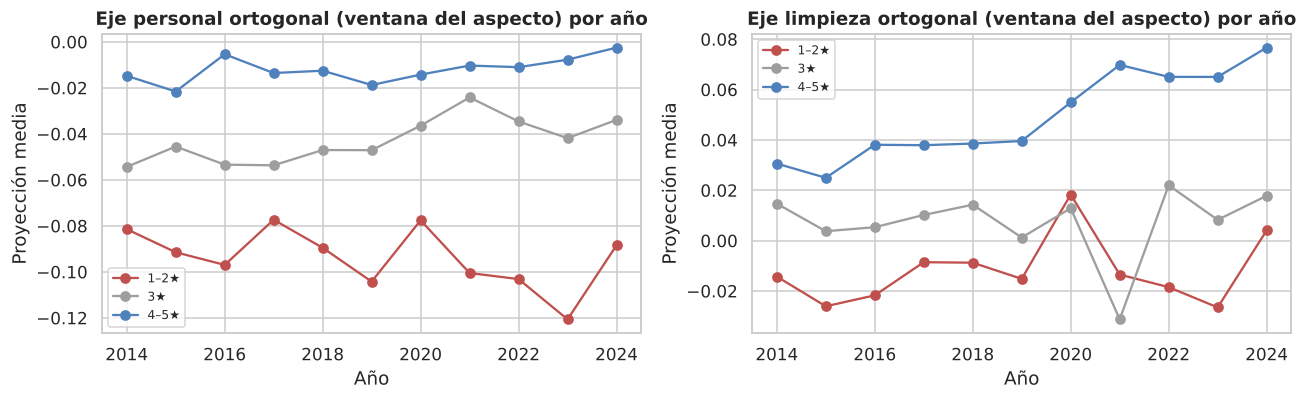

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=False)
for ax, eje in zip(axes, EJES):
    g = en.groupby(['year', 'label3'])[f'proy_{eje}_aspecto_ort'].mean().unstack()
    for lab in ['neg', 'neu', 'pos']:
        ax.plot(g.index, g[lab], 'o-', color=COL[lab], label={'neg': '1–2★', 'neu': '3★', 'pos': '4–5★'}[lab])
    ax.set_title(f'Eje {eje} ortogonal (ventana del aspecto) por año'); ax.set_xlabel('Año'); ax.set_ylabel('Proyección media')
    ax.legend(fontsize=8)
guardar_figura('11_proyecciones_por_anio')

Con los ejes ya corregidos, las reseñas de 4–5★ quedan por encima de las de 1–2★ todos los años, en ambos ejes: la señal del aspecto es consistente en el tiempo. En limpieza, la proyección de las positivas sube desde 2020. Puede ser un efecto de los protocolos de higiene de la pandemia, que hicieron más visible la limpieza en las reseñas, pero el dato no permite afirmarlo.

# 8. Evaluación final del clasificador y análisis de errores

## 8.1 Tabla comparativa

In [40]:
tabla_resultados()

,C,F1-macro CV,F1-macro,Exactitud balanceada,Precisión neg.,Recall neg.,Exactitud,IC95 F1-macro,IC95 recall neg.
Modelo,,,,,,,,,
Línea base: siempre positiva,—,—,0.490,0.500,0.000,0.000,0.960,"[0.488, 0.492]","[0.000, 0.000]"
Línea base: solo longitud,—,—,0.456,0.574,0.058,0.454,0.685,"[0.441, 0.470]","[0.365, 0.544]"
Binaria (unigramas),16,0.896,0.885,0.877,0.798,0.762,0.983,"[0.854, 0.914]","[0.686, 0.837]"
BoW (unigramas),1,0.882,0.903,0.918,0.786,0.846,0.985,"[0.876, 0.929]","[0.781, 0.907]"
TF-IDF (unigramas),64,0.903,0.913,0.919,0.821,0.846,0.987,"[0.887, 0.935]","[0.788, 0.906]"
TF-IDF (uni + bigramas),16,0.912,0.916,0.927,0.818,0.862,0.987,"[0.890, 0.939]","[0.800, 0.919]"
TF-IDF (uni + bigramas) + lematización,64,0.909,0.913,0.919,0.821,0.846,0.987,"[0.887, 0.938]","[0.780, 0.904]"
TF-IDF (uni + bigramas) con nombres propios,64,0.913,0.910,0.912,0.824,0.831,0.986,"[0.884, 0.934]","[0.766, 0.895]"
Word2Vec promedio,64,0.806,0.813,0.949,0.494,0.938,0.960,"[0.784, 0.840]","[0.893, 0.978]"


El mejor modelo es **TF-IDF con unigramas y bigramas** sobre el texto limpio y enmascarado: F1-macro de 0,916 (IC95 [0,890; 0,939]), exactitud balanceada de 0,927, y precisión y recall de la clase negativa de 0,818 y 0,862. Ningún experimento de preprocesamiento lo mejora de forma significativa, y Word2Vec solo gana cuando hay pocas etiquetas (6.5).

## 8.2 Validación temporal

El anteproyecto advertía que el 70 % de las negativas está en 2014–2019 y que el modelo podría aprender vocabulario de una época. Se entrena con 2014–2021 y se prueba con 2022–2024. Para separar el efecto del **tiempo** del efecto del **tamaño de entrenamiento**, se compara con 5 particiones aleatorias del mismo tamaño.

In [41]:
m_T = Pipeline([('vec', vec_best()), ('clf', LogisticRegression(C=C_best, class_weight='balanced', max_iter=5000))])
m_T.fit(A.loc[tr_T, 'texto_modelo'], A.loc[tr_T, 'y'])
y_T = A.loc[te_T, 'y'].values
pred_T = m_T.predict(A.loc[te_T, 'texto_modelo'])
met_T = metricas(y_T, pred_T)
(fl, fh), (rl, rh) = ic_bootstrap(y_T, pred_T)

control = []
for s in range(5):
    sub, resto = train_test_split(A.index, train_size=len(tr_T), stratify=A['y'], random_state=s)
    mm = Pipeline([('vec', vec_best()), ('clf', LogisticRegression(C=C_best, class_weight='balanced', max_iter=5000))])
    mm.fit(A.loc[sub, 'texto_modelo'], A.loc[sub, 'y'])
    control.append(f1_score(A.loc[resto, 'y'], mm.predict(A.loc[resto, 'texto_modelo']), average='macro'))

print(f"Entrenamiento 2014–2021: {len(tr_T):,} reseñas ({A.loc[tr_T, 'y'].mean():.1%} negativas) | "
      f"prueba 2022–2024: {len(te_T):,} ({y_T.mean():.1%} negativas, {y_T.sum()} casos)")
print(f"Temporal: F1-macro {met_T['F1-macro']:.3f} [{fl:.3f}, {fh:.3f}] | recall neg. {met_T['Recall neg.']:.3f} [{rl:.3f}, {rh:.3f}] | "
      f"precisión neg. {met_T['Precisión neg.']:.3f} | exactitud balanceada {met_T['Exactitud balanceada']:.3f}")
print(f"Control aleatorio con el mismo tamaño: F1-macro {np.mean(control):.3f} (mín. {np.min(control):.3f}, máx. {np.max(control):.3f})")

Entrenamiento 2014–2021: 8,704 reseñas (5.7% negativas) | prueba 2022–2024: 7,733 (2.0% negativas, 152 casos)
Temporal: F1-macro 0.931 [0.909, 0.951] | recall neg. 0.888 [0.831, 0.937] | precisión neg. 0.844 | exactitud balanceada 0.942
Control aleatorio con el mismo tamaño: F1-macro 0.910 (mín. 0.904, máx. 0.914)


**El supuesto de deriva temporal no se confirma.** Entrenado solo con 2014–2021, el modelo obtiene en 2022–2024 un F1-macro de 0,931 (IC95 [0,909; 0,951]). Las cinco particiones aleatorias del mismo tamaño quedan entre 0,904 y 0,914. La proporción de negativas cambia mucho entre periodos (5,7 % frente a 2,0 %), y eso afecta al F1. Por eso conviene mirar también las métricas que no dependen de la prevalencia: el recall de la clase negativa (0,888) y la exactitud balanceada (0,942) también son iguales o mejores que en la partición aleatoria (0,862 y 0,927). El vocabulario de la queja no cambió lo suficiente para dañar el modelo. Una salvedad: la prueba temporal solo tiene 152 negativas, y el intervalo de su recall va de 0,831 a 0,937.

## 8.3 Análisis de errores

In [42]:
err = A.loc[te_A, ['Review', 'Rating', 'y', 'n_palabras']].copy()
err['p_neg'] = p_te
err['pred'] = pred_te
fn = err[(err['y'] == 1) & (err['pred'] == 0)]
fp = err[(err['y'] == 0) & (err['pred'] == 1)]
print(f'Falsos negativos (negativas que el modelo no detecta): {len(fn)} -> por calificación {fn.Rating.value_counts().sort_index().to_dict()}')
print(f'Falsos positivos (alarmas sobre reseñas 4–5★): {len(fp)} -> por calificación {fp.Rating.value_counts().sort_index().to_dict()}')
print(f"Predicciones de baja confianza (0,4 ≤ p ≤ 0,6): {int(err['p_neg'].between(0.4, 0.6).sum())}")

err['longitud'] = pd.qcut(err['n_palabras'], 3, labels=['corta', 'media', 'larga'])
err['error'] = (err['y'] != err['pred']).astype(int)
display(err.groupby('longitud', observed=True)['error'].agg(tasa='mean', errores='sum', reseñas='size').round(4))

print('\nFalsos negativos con menor probabilidad de ser negativas:')
for _, r in fn.nsmallest(3, 'p_neg').iterrows():
    print(f"   [{r.Rating}★ · p={r.p_neg:.2f}] {r.Review[:230]}…")
print('\nFalsos positivos con mayor probabilidad de ser negativas:')
for _, r in fp.nlargest(3, 'p_neg').iterrows():
    print(f"   [{r.Rating}★ · p={r.p_neg:.2f}] {r.Review[:230]}…")

Falsos negativos (negativas que el modelo no detecta): 18 -> por calificación {1: 7, 2: 11}
Falsos positivos (alarmas sobre reseñas 4–5★): 25 -> por calificación {4: 20, 5: 5}
Predicciones de baja confianza (0,4 ≤ p ≤ 0,6): 20


,tasa,errores,reseñas
longitud,,,
corta,0.0106,12,1137
media,0.0103,11,1071
larga,0.0185,20,1080



Falsos negativos con menor probabilidad de ser negativas:
   [2★ · p=0.00] This hotel has been consistently good over the  years.  I love the location with its amazing views of the Baudha.  it has a nice leisurely feel to it which is quiet relaxing.  the club rooms are worth the extra spend.…
   [2★ · p=0.02] Overall, the hotel is quite comfortable, with a full range of amenities,  and in a good location. However, their security was extremely slow to respond to a security incident at the hotel, leaving my colleagues and me feeling unsa…
   [1★ · p=0.02] The hotel is dated, the staff jaded, and the food inedible.  Highly suggest the staff (and / or the management) go and visit some decent properties in locations similar to what they have.  The property itself is a gem, sadly every…

Falsos positivos con mayor probabilidad de ser negativas:
   [4★ · p=0.99] Everything is fine but the hospitality at kitchen  department is worst .The item on the menu aren't available .When we tried to ord

Los errores tienen tres causas, y ninguna es un fallo aleatorio:

1. **Reseñas mixtas (la mayoría de los falsos positivos).** 20 de los 25 falsos positivos son reseñas de 4★ con quejas explícitas: "the hospitality at kitchen department is worst", "not up to 5 star standard". El texto critica un aspecto y la calificación premia el conjunto. El modelo no se equivoca al leer la queja; se equivoca porque la etiqueta es de la reseña completa.
2. **Calificación que contradice el texto.** El falso negativo más seguro (p = 0,00) es una reseña de 2★ que dice "consistently good", "I love the location", "worth the extra spend". Lo más probable es un error del huésped al calificar.
3. **Crítica sin palabras negativas típicas.** "The hotel is dated, the staff jaded, and the food inedible… Highly suggest…": las palabras que delatan la queja son poco frecuentes, y *highly* y *gem* empujan hacia positiva.

La tasa de error en las reseñas largas (1,85 %) casi duplica la de las cortas y medianas (1,06 % y 1,03 %): cuanto más larga la reseña, más aspectos mezcla. Ese es el argumento para bajar al nivel de frase en la sección 9.6.

## 8.4 Función `predict_sentiment`

Aplica la misma limpieza del entrenamiento (incluido el enmascarado de nombres) y devuelve la etiqueta y la probabilidad de que la reseña sea negativa.

In [43]:
def predict_sentiment(texto, umbral=0.5):
    p = float(MEJOR.predict_proba([enmascarar(clean_text(texto))])[0, 1])
    return {'sentimiento': 'negativo' if p >= umbral else 'positivo', 'p_negativa': round(p, 3)}

for t in ['The staff were wonderful and the breakfast buffet was delicious.',
          'The room was not clean and nobody at the reception cared.',
          'Great location, but for a five star hotel the price is too high and the wifi never worked.',
          'Not bad at all, I would definitely come back.']:
    print(f'{predict_sentiment(t)} <- {t}')
print('\nCoeficientes involucrados en el último ejemplo:',
      {t: round(float(coef.get(t, np.nan)), 2) for t in ['not', 'bad', 'not bad', 'definitely', 'come']})
print('Reseñas de entrenamiento con el bigrama "not bad":', int(A.loc[tr_A, 'texto_modelo'].str.contains(r'\bnot bad\b').sum()))

{'sentimiento': 'positivo', 'p_negativa': 0.002} <- The staff were wonderful and the breakfast buffet was delicious.
{'sentimiento': 'negativo', 'p_negativa': 0.97} <- The room was not clean and nobody at the reception cared.
{'sentimiento': 'negativo', 'p_negativa': 0.889} <- Great location, but for a five star hotel the price is too high and the wifi never worked.
{'sentimiento': 'negativo', 'p_negativa': 0.943} <- Not bad at all, I would definitely come back.

Coeficientes involucrados en el último ejemplo: {'not': 18.04, 'bad': 11.5, 'not bad': -1.92, 'definitely': -2.32, 'come': -2.11}
Reseñas de entrenamiento con el bigrama "not bad": 41


Los tres primeros ejemplos se clasifican bien, incluida la reseña mixta del tercero. El cuarto, **"Not bad at all, I would definitely come back"**, sale negativo con p = 0,943, y es un error instructivo. El modelo suma *not* (18,04) y *bad* (11,50) como palabras separadas; el bigrama *not bad* tiene un coeficiente de −1,92, demasiado débil para compensarlas, porque aparece en solo 41 reseñas de entrenamiento. Es el límite estructural de la bolsa de palabras: no entiende que la negación invierte el sentido de la palabra siguiente. Las alternativas son marcar el alcance de la negación (convertir "not bad" en un solo token) o usar modelos contextuales como BERT (trabajo futuro).

# 9. Buscador de comentarios por aspecto

El administrador escribe "piscina" o "buffet" y necesita ver los comentarios sobre ese aspecto, **en cualquier idioma**, y saber qué se critica de él. Esto es un problema de recuperación de información: la salida no es una etiqueta, es una lista ordenada.

Las cuatro decisiones de diseño previas de la sesión de IR:

| Decisión | Elección |
|:--|:--|
| Campos | El texto completo de la reseña; el documento es la reseña |
| Modelo v1 | BM25 (`k1 = 1.2`, `b = 0.75`, sin ajustar sobre la evaluación) |
| Métrica principal | P@10 y **MAP@10**: el administrador lee la primera página y le importa que lo relevante salga arriba |
| Riesgo | Que una consulta en español no encuentre las reseñas en inglés (desajuste de vocabulario entre idiomas) |

Se comparan cuatro sistemas: **BM25**, **BM25 con expansión de consulta por Word2Vec**, **recuperación densa con Sentence-BERT multilingüe** y una **fusión híbrida con RRF**.

## 9.1 Índice BM25

La tokenización es la de la sesión de IR (`[a-z0-9]+`, sin stop words). Se agrega un paso: quitar las tildes, para que "habitación" no se parta en "habitaci" y "n". El índice cubre las 17.976 reseñas, en todos los idiomas.

score(q, d) = Σ idf(t) · tf(t,d) · (k1 + 1) / ( tf(t,d) + k1 · (1 − b + b · |d| / avgdl) ),  con idf(t) = ln( (N − df + 0,5) / (df + 0,5) + 1 )

In [44]:
import unicodedata
TOK_IR = re.compile(r'[a-z0-9]+')

def tokens_ir(texto):
    t = unicodedata.normalize('NFKD', str(texto).lower().replace('…', ' ')).encode('ascii', 'ignore').decode()
    return [w for w in TOK_IR.findall(t) if w not in CUSTOM_STOP_WORDS]

cv_ir = CountVectorizer(tokenizer=tokens_ir, lowercase=False, token_pattern=None)
TF_IR = cv_ir.fit_transform(df['Review']).tocoo()
VOC_IR = cv_ir.vocabulary_
N_DOCS = TF_IR.shape[0]
dl = np.asarray(TF_IR.sum(axis=1)).ravel()
avgdl = dl.mean()
df_term = np.bincount(TF_IR.col, minlength=TF_IR.shape[1])
IDF_IR = np.log((N_DOCS - df_term + 0.5) / (df_term + 0.5) + 1.0)
K1, B_BM25 = 1.2, 0.75
peso = IDF_IR[TF_IR.col] * TF_IR.data * (K1 + 1) / (TF_IR.data + K1 * (1 - B_BM25 + B_BM25 * dl[TF_IR.row] / avgdl))
W_BM25 = sp.csc_matrix((peso.astype(np.float32), (TF_IR.row, TF_IR.col)), shape=TF_IR.shape)
print(f'Documentos: {N_DOCS:,} | términos: {len(VOC_IR):,} | longitud media (avgdl): {avgdl:.1f} tokens')

def puntajes_bm25(pesos_consulta):
    s = np.zeros(N_DOCS, dtype=np.float32)
    for t, w in pesos_consulta.items():
        if t in VOC_IR:
            s += w * W_BM25[:, VOC_IR[t]].toarray().ravel()
    return s

def top_k(s, k=100):
    if s.max() <= 0:
        return np.array([], dtype=int)
    k = min(k, int((s > 0).sum()))
    idx = np.argpartition(-s, k - 1)[:k]
    return idx[np.lexsort((idx, -s[idx]))]        # desempate estable por doc_id

def run_bm25(q, k=100):
    return top_k(puntajes_bm25({t: 1.0 for t in tokens_ir(q)}), k)

Documentos: 17,976 | términos: 37,188 | longitud media (avgdl): 45.4 tokens


## 9.2 Expansión de consulta con Word2Vec

La sesión de IR propone la expansión como remedio al desajuste de vocabulario. A cada término de la consulta se le agregan hasta 3 vecinos del Word2Vec del dominio (sección 6) que cumplan cuatro condiciones:

- similitud coseno ≥ 0,70;
- existir en el índice;
- no ser stop words, números ni nombres propios;
- que el término original no esté en más del 25 % de las reseñas (expandir "hotel" o "room" solo agrega ruido).

Los términos agregados pesan 0,5.

In [45]:
DF_RATIO = dict(zip(cv_ir.get_feature_names_out(), df_term / N_DOCS))

def expandir(q, k=3, umbral=0.70, peso_exp=0.5, max_df=0.25):
    toks = tokens_ir(q)
    pesos, agregados = {t: 1.0 for t in toks}, []
    for t in toks:
        if t not in V.key_to_index or DF_RATIO.get(t, 0) > max_df:
            continue
        n_add = 0
        for vecino, sim in V.most_similar(t, topn=15):
            if n_add == k or sim < umbral:
                break
            if vecino in VOC_IR and vecino not in pesos and vecino not in CUSTOM_STOP_WORDS \
                    and not vecino.isdigit() and vecino not in NP_SET:
                pesos[vecino] = peso_exp
                agregados.append(f'{t}→{vecino} ({sim:.2f})')
                n_add += 1
    return pesos, agregados

def run_bm25_exp(q, k=100):
    return top_k(puntajes_bm25(expandir(q)[0]), k)

for q in ['swimming pool', 'breakfast buffet', 'slow wifi internet connection', 'piscina']:
    print(f"{q:32s} -> {', '.join(expandir(q)[1]) or '(sin expansión: ningún término en el vocabulario inglés)'}")

swimming pool                    -> swimming→jacuzzi (0.78), swimming→indoor (0.77), swimming→swiming (0.76), pool→pools (0.72), pool→whirlpool (0.70)
breakfast buffet                 -> breakfast→comprehensive (0.71), buffet→spread (0.76), buffet→buffets (0.75), buffet→ala (0.72)
slow wifi internet connection    -> wifi→fi (0.83), wifi→wi (0.81), wifi→connectivity (0.72), internet→speed (0.74), internet→signal (0.71), internet→spotty (0.71), connection→unreliable (0.73), connection→weak (0.71), connection→unstable (0.70)
piscina                          -> (sin expansión: ningún término en el vocabulario inglés)


La expansión ayuda y también arrastra ruido, y por eso hay que medirla:

- **Ayuda** con variantes y errores de tipeo (*swiming*, *buffets*, *wi*/*fi* de "wi-fi") y con síntomas del problema (*connection* → *unreliable, weak, unstable*; *internet* → *signal, spotty*).
- **Arrastra ruido** cuando el vecino es del mismo tema pero no del mismo concepto: *breakfast* → *comprehensive*, *buffet* → *ala* (de "à la carte", lo contrario de un buffet), *swimming* → *indoor*.
- **No sirve en español**: "piscina" no está en el vocabulario de un Word2Vec entrenado en inglés.

La evaluación con MAP (9.7) decide si el balance es positivo.

## 9.3 Recuperación densa con Sentence-BERT multilingüe

`paraphrase-multilingual-MiniLM-L12-v2` lleva frases de más de 50 idiomas al **mismo espacio** de 384 dimensiones. Es un *bi-encoder*, como el reranker de FiQA del taller: consulta y reseña se codifican por separado y se comparan con coseno. Así, "piscina" puede encontrar reseñas que dicen "pool". Las reseñas se codifican una sola vez (unos 7 minutos en CPU) y se guardan en `cache/`. Una limitación: el modelo lee como máximo 128 *wordpieces*, así que en las reseñas largas solo ve el comienzo.

In [46]:
import hashlib, torch
from sentence_transformers import SentenceTransformer
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

sbert = SentenceTransformer(SBERT_NAME, device='cpu', model_kwargs={'torch_dtype': torch.float32})
huella = hashlib.md5('\n'.join(df['Review']).encode()).hexdigest()
f_emb, f_huella = CACHE / 'emb_resenas.npy', CACHE / 'emb_resenas.md5'
t0 = time.time()
if f_emb.exists() and f_huella.exists() and f_huella.read_text() == huella:
    EMB = np.load(f_emb)
else:
    EMB = sbert.encode(df['Review'].tolist(), batch_size=64, normalize_embeddings=True,
                       show_progress_bar=False).astype(np.float32)
    np.save(f_emb, EMB)
    f_huella.write_text(huella)
print(f'Embeddings: {EMB.shape} | longitud máxima: {sbert.max_seq_length} wordpieces | {time.time() - t0:.0f} s')

def run_densa(q, k=100):
    s = EMB @ sbert.encode([q], normalize_embeddings=True)[0]
    idx = np.argpartition(-s, k - 1)[:k]
    return idx[np.lexsort((idx, -s[idx]))]

Embeddings: (17976, 384) | longitud máxima: 128 wordpieces | 0 s


## 9.4 Fusión híbrida (RRF) y selección automática

La fusión por rango recíproco (RRF, `c = 60`, ejercicio 12 del taller) combina el top 100 de BM25 con expansión y el top 100 de la búsqueda densa:

RRF(d) = Σ_sistemas 1 / (c + posición de d)

Para el buscador final se define además una regla **automática** que no requiere detectar el idioma (langdetect falla con consultas de una o dos palabras). Si **todas** las palabras de la consulta están en el vocabulario inglés de Word2Vec, se usa la búsqueda híbrida; si no, la densa.

In [47]:
def run_hibrida(q, k=100, c=60):
    fus = {}
    for ranking in (run_bm25_exp(q), run_densa(q)):
        for pos, d in enumerate(ranking, 1):
            fus[d] = fus.get(d, 0.0) + 1.0 / (c + pos)
    return np.array(sorted(fus, key=lambda d: (-fus[d], d))[:k], dtype=int)

def consulta_en_ingles(q):
    toks = tokens_ir(q)
    return len(toks) > 0 and all(t in V.key_to_index for t in toks)

def run_auto(q, k=100):
    return run_hibrida(q, k) if consulta_en_ingles(q) else run_densa(q, k)

SISTEMAS = {'BM25': run_bm25, 'BM25 + expansión W2V': run_bm25_exp, 'Densa (Sentence-BERT)': run_densa, 'Híbrida (RRF)': run_hibrida}
for q in ['piscina', 'swimming pool', 'wifi lento', 'personal grosero']:
    print(f"{q:18s} -> {'híbrida' if consulta_en_ingles(q) else 'densa'}")

piscina            -> densa
swimming pool      -> híbrida
wifi lento         -> densa
personal grosero   -> densa


## 9.5 La herramienta: `buscar()`

Devuelve las reseñas más relevantes con su calificación, su idioma y la probabilidad de que sea negativa (solo para reseñas en inglés, con el clasificador de la sección 4). También muestra **la frase de la reseña más parecida a la consulta**, elegida con Sentence-BERT, para que el administrador vea de inmediato qué dice sobre el aspecto.

In [48]:
df['p_neg'] = np.nan
df.loc[en.index, 'p_neg'] = MEJOR.predict_proba(en['texto_modelo'])[:, 1]

def frase_mas_cercana(texto, q_emb, largo=200):
    frases = [s.strip() for s in re.split(r'(?<=[.!?])\s+|\n+', str(texto)) if len(s.split()) >= 3] or [str(texto)]
    e = sbert.encode(frases, normalize_embeddings=True)
    f = frases[int(np.argmax(e @ q_emb))]
    return f if len(f) <= largo else f[:largo] + '…'

def buscar(consulta, k=10, sistema='auto'):
    fn = run_auto if sistema == 'auto' else SISTEMAS[sistema]
    idx = fn(consulta)[:k]
    q_emb = sbert.encode([consulta], normalize_embeddings=True)[0]
    res = df.iloc[idx][['doc_id', 'Rating', 'lang', 'p_neg', 'Review']].copy()
    res['frase más cercana a la consulta'] = res['Review'].apply(lambda t: frase_mas_cercana(t, q_emb))
    res.insert(0, 'posición', range(1, len(res) + 1))
    res['p_neg'] = res['p_neg'].round(2)
    return res.drop(columns='Review').rename(columns={'Rating': '★', 'lang': 'idioma', 'p_neg': 'p(negativa)'}).set_index('posición')

for q in ['piscina', 'wifi lento']:
    display(Markdown(f"**Consulta: «{q}»** · sistema: {'híbrido' if consulta_en_ingles(q) else 'denso'}"))
    display(buscar(q, k=5))

**Consulta: «piscina»** · sistema: denso

,doc_id,★,idioma,p(negativa),frase más cercana a la consulta
posición,,,,,
1,16707,5,en,0.01,"The swimming pool is very suitable for summer and not crowded as well, would definitely recommend to swimmers who prefer their privacy."
2,16247,2,en,0.98,"Pros: great views thats about it.Cons: the swimming pool water was murky, they somehow messed up with the amount of chemicals to put in."
3,8143,5,en,0.00,"Although the pool is open all year, it is cool during this season."
4,17629,5,en,0.00,The swimming pool is amazing with a restaurant/bar in front of it.
5,16040,5,en,0.00,The pool was great!


**Consulta: «wifi lento»** · sistema: denso

,doc_id,★,idioma,p(negativa),frase más cercana a la consulta
posición,,,,,
1,14228,4,en,0.32,It is so slow and not working.
2,9639,4,en,0.01,Free wifi is very slow.
3,9491,4,en,0.03,Wifi is decent but the max they provide for an individual is 2mbps speed and that one is also chargeable...
4,11578,4,en,0.04,"Food, rooms and service was 4-start on an international benchmark, but I've no doubt counts at or near the top of what's available here.WiFi speeds are dece..."
5,11694,4,en,0.00,"Wi-fi: For wi-fi it's 7.50usd per day, or you can buy a coupon at the front desk and get two devices activated for 10usd per day."


Con una consulta en español, el buscador devuelve reseñas en inglés sobre el aspecto. Para "piscina", las cinco hablan de la piscina; una de ellas es una queja de 2★ ("the swimming pool water was murky", p = 0,98). Para "wifi lento", las cinco hablan de un wifi lento o con cobro ("Free wifi is very slow", "the max they provide… is 2mbps speed and that one is also chargeable"). La columna de la frase más cercana le ahorra al administrador leer la reseña completa.

## 9.6 Mapa de quejas por aspecto

La calificación es de la reseña completa, pero una reseña de 5★ puede quejarse del wifi en una frase. Por eso el análisis baja **a nivel de frase**, como la recuperación por pasajes de la sesión de IR. Primero se toman todas las frases en inglés que mencionan el aspecto, usando un léxico armado con los vecinos Word2Vec de la sección 6.3. Después, el clasificador de la sección 4 estima si cada frase es negativa.

La columna "palabras de queja" lista las palabras que aparecen proporcionalmente más en las frases negativas de ese aspecto que en las frases negativas de los demás aspectos, es decir, lo que distingue la queja de ese aspecto.

Dos advertencias. El clasificador se entrenó con reseñas completas, no con frases, y por eso se valida con 100 frases etiquetadas por el equipo (sección 9.8). Además, una frase puede mencionar el aspecto sin que la queja sea sobre él.

In [49]:
ASPECTOS = {
    'Piscina': ['pool', 'pools', 'swimming', 'jacuzzi', 'poolside'],
    'Desayuno y buffet': ['breakfast', 'buffet', 'buffets', 'bfast'],
    'Restaurante y comida': ['food', 'restaurant', 'restaurants', 'dinner', 'lunch', 'menu', 'dishes'],
    'Wifi e internet': ['wifi', 'wi-fi', 'wi fi', 'internet', 'connectivity'],
    'Spa': ['spa', 'massage', 'massages', 'sauna', 'steam'],
    'Personal': ['staff', 'reception', 'receptionist', 'front desk', 'waiter', 'waiters', 'manager'],
    'Habitación y baño': ['room', 'rooms', 'bed', 'bathroom', 'shower', 'toilet'],
    'Ruido': ['noise', 'noisy', 'loud', 'quiet', 'peaceful'],
    'Ubicación': ['location', 'located', 'walking distance', 'neighborhood', 'neighbourhood'],
    'Precio': ['price', 'prices', 'expensive', 'overpriced', 'value', 'money', 'worth'],
    'Traslado aeropuerto': ['airport', 'pickup', 'pick up', 'transfer', 'shuttle', 'taxi']}

filas = []
for i, (texto, rating) in zip(en.index, zip(en['Review'], en['Rating'])):
    for s in re.split(r'(?<=[.!?])\s+|\n+', str(texto)):
        if len(s.split()) >= 4:
            filas.append((i, rating, s.strip()))
FRASES = pd.DataFrame(filas, columns=['idx', 'Rating', 'frase'])
FRASES['texto'] = FRASES['frase'].apply(clean_text).apply(enmascarar)
FRASES['p_neg'] = MEJOR.predict_proba(FRASES['texto'])[:, 1]
FRASES['negativa'] = (FRASES['p_neg'] >= 0.5).astype(int)
tasa_global = FRASES['negativa'].mean()
print(f'Frases: {len(FRASES):,} de {len(en):,} reseñas en inglés | frases negativas en todo el corpus: {tasa_global:.1%}')

def lift_quejas(sub, terminos, n=8, min_c=5):
    """Palabras sobrerrepresentadas en las frases negativas del aspecto frente a las frases negativas de los demás."""
    excl = set(' '.join(terminos).split()) | NEGATIONS_TO_KEEP
    neg = sub[sub['negativa'] == 1]
    otras = FRASES[(FRASES['negativa'] == 1) & ~FRASES.index.isin(sub.index)]
    cn = Counter(w for t in neg['texto'] for w in set(t.split()) if w not in excl)
    co = Counter(w for t in otras['texto'] for w in set(t.split()))
    lift = {w: (c / len(neg)) / ((co[w] + 1) / (len(otras) + 1)) for w, c in cn.items() if c >= min_c}
    return ', '.join(w for w, _ in sorted(lift.items(), key=lambda x: -x[1])[:n])

mapa = []
for asp, terminos in ASPECTOS.items():
    pat = re.compile(r'\b(' + '|'.join(map(re.escape, terminos)) + r')\b', re.I)
    sub = FRASES[FRASES['frase'].str.contains(pat)]
    mapa.append({'aspecto': asp, 'reseñas que lo mencionan': sub['idx'].nunique(),
                 '% de esas reseñas con 1–2★': round(100 * en.loc[sub['idx'].unique(), 'Rating'].le(2).mean(), 1),
                 'frases': len(sub), '% frases negativas': round(100 * sub['negativa'].mean(), 1),
                 'frases negativas': int(sub['negativa'].sum()), 'palabras de queja': lift_quejas(sub, terminos)})
MAPA = pd.DataFrame(mapa).set_index('aspecto').sort_values('% frases negativas', ascending=False)
display(MAPA)

Frases: 94,920 de 17,262 reseñas en inglés | frases negativas en todo el corpus: 6.5%


,reseñas que lo mencionan,% de esas reseñas con 1–2★,frases,% frases negativas,frases negativas,palabras de queja
aspecto,,,,,,
Precio,1995,10.4,2398,22.8,547,"exchange, save, cheaper, taxis, basically, rates, reasonable, spend"
Wifi e internet,976,8.1,1122,19.2,215,"connect, free, connection, signal, complimentary, access, included, slow"
Habitación y baño,8662,5.2,13409,11.9,1591,"allotted, tiny, twin, deluxe, damp, leaking, stuffy, bathtub"
Ruido,1599,3.9,1790,7.7,137,"music, street, hear, construction, windows, party, early, away"
Traslado aeropuerto,1472,4.5,1789,6.4,115,"drop, representative, driver, flight, car, local, sent, arrived"
Personal,9956,3.7,13461,5.6,756,"unfriendly, accommodating, names, helpful, trained, duty, delay, training"
Desayuno y buffet,4185,4.3,4701,5.5,259,"spread, meals, package, limited, tasty, lunch, evening, choice"
Restaurante y comida,10144,3.0,13703,4.6,635,"salad, ate, costly, tasty, eve, served, buffet, overpriced"
Piscina,3010,3.1,3351,4.3,144,"swim, heated, use, drinks, clean, dirty, area, looked"


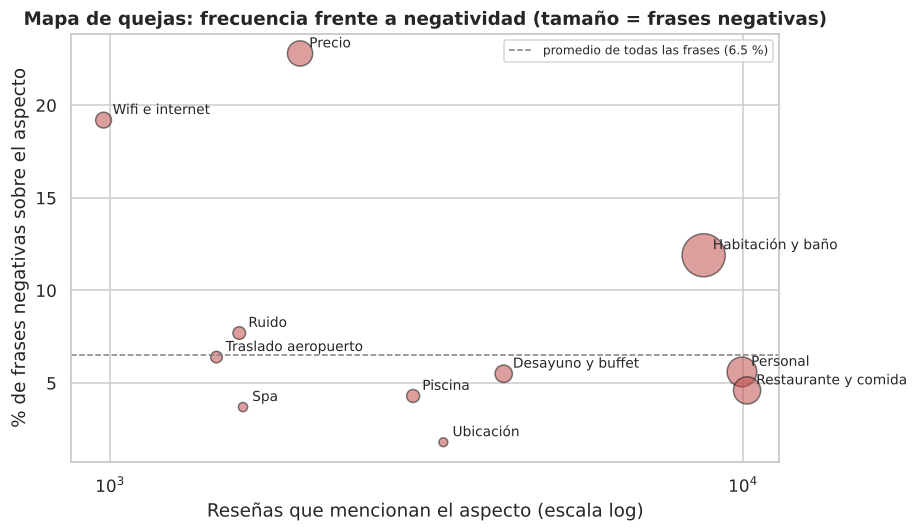


Precio: ejemplos de frases negativas
   · Don't trust the price quoted to you because when you checkout, they will add all the taxes.
   · - Money: Ask for prices inclusive of service charge (10%) and VAT (13%).
   · The stay was was worth the money that I had paid.



Wifi e internet: ejemplos de frases negativas
   · Only the wifi in the rooms had to be paid extra for, and way too much!
   · We had no problems with wifi though.
   · Wifi's not free and I mean who "PAYS" for wifi these days in a 5 star hotel.There were neither slippers nor wardrobe.



Habitación y baño: ejemplos de frases negativas
   · Blackout in the rooms is not well arranged as curtains are short so light come into the room not to mention the Crowl as if they are sitting in your room at 5 AM alarm...
   · I am with my family for a vacation and booked this property by just trusting the name but it's shocking that even after bearing the brand the rooms are in a mess.
   · No free wifi in room?


In [50]:
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.scatter(MAPA['reseñas que lo mencionan'], MAPA['% frases negativas'], s=MAPA['frases negativas'] / 2,
           color=COL['neg'], alpha=0.55, edgecolor='k')
for asp, r in MAPA.iterrows():
    ax.annotate(asp, (r['reseñas que lo mencionan'], r['% frases negativas']), xytext=(6, 4), textcoords='offset points', fontsize=9)
ax.set_xscale('log')
ax.axhline(100 * tasa_global, color='gray', ls='--', lw=1, label=f'promedio de todas las frases ({100 * tasa_global:.1f} %)')
ax.legend(loc='upper right', fontsize=8)
ax.set_xlabel('Reseñas que mencionan el aspecto (escala log)'); ax.set_ylabel('% de frases negativas sobre el aspecto')
ax.set_title('Mapa de quejas: frecuencia frente a negatividad (tamaño = frases negativas)')
guardar_figura('12_mapa_de_quejas')

for asp in MAPA.index[:3]:
    pat = re.compile(r'\b(' + '|'.join(map(re.escape, ASPECTOS[asp])) + r')\b', re.I)
    sub = FRASES[FRASES['frase'].str.contains(pat) & (FRASES['negativa'] == 1)]
    print(f'\n{asp}: ejemplos de frases negativas')
    for f in sub.sample(min(3, len(sub)), random_state=RANDOM_STATE)['frase']:
        print(f'   · {f[:170]}')

**Qué dice el mapa.** El promedio de frases negativas en el corpus es del 6,5 %. Tres aspectos se salen de ese patrón:

| Aspecto | % frases negativas | Qué distingue la queja | Lectura |
|:--|--:|:--|:--|
| **Precio** | 22,8 % | *exchange, cheaper, rates, taxis* | El problema no es solo cuánto cuesta: son las tarifas, los impuestos y el cambio de moneda ("Don't trust the price quoted… they will add all the taxes") |
| **Wifi e internet** | 19,2 % | *free, complimentary, included, connection, signal, slow* | Dos quejas: que se cobre aparte y que no funcione. Solo el 8,1 % de esas reseñas tiene 1–2★: es un **dolor oculto** que la calificación no muestra |
| **Habitación y baño** | 11,9 % | *tiny, damp, leaking, stuffy, bathtub* | Es el mayor **volumen**: 1.591 frases negativas, más que cualquier otro aspecto |

En el otro extremo, ubicación (1,8 %), spa (3,7 %) y piscina (4,3 %) son fortalezas. El ruido (7,7 %) tiene fuentes concretas: *music, street, construction, windows, party*.

Para un administrador, esto se traduce en una priorización. Incluir el wifi en la tarifa y mejorar la señal es probablemente la acción más barata frente al tamaño de la queja. La transparencia de tarifas ataca el aspecto más negativo. El mantenimiento de habitaciones y baños es el que más quejas acumula.

**Advertencia.** Entre los ejemplos hay falsos positivos claros: "We had no problems with wifi though." y "The stay was was worth the money that I had paid." se marcan como negativas por *no, problems* y *paid*. La validación de 9.8 mide el efecto: precisión de 0,680. Por eso los porcentajes del mapa sirven para **comparar aspectos entre sí**, no como cifras absolutas.

## 9.7 Evaluación del buscador con MAP

Sin juicios de relevancia no hay benchmark (sesión de IR, paradigma Cranfield). El corpus de hoteles no los trae, así que el equipo los construye con *pooling*, como en TREC:

1. Se definen **10 necesidades de información** de un administrador, con un criterio de relevancia explícito. Cinco tienen versión en inglés y en español, para medir cuánto se pierde al consultar en español. En total son **15 consultas**.
2. Para cada necesidad se unen los **top 10 de los 4 sistemas** en todas sus consultas. Ese es el *pool*.
3. Isabel y Esteban juzgan cada reseña del pool **sin ver qué sistema la trajo ni su calificación**. Se reparten las reseñas por mitades, y 3 por necesidad (30 en total) las juzgan ambos para medir el acuerdo con kappa de Cohen.
4. Con los juicios se calculan **P@10, MAP@10, nDCG@10 y MRR@10**. Una reseña recuperada que no está en el pool cuenta como no relevante, la convención de TREC.

AP@10 = (1 / mín(R, 10)) · Σ_{i ≤ 10, d_i relevante} P@i, donde R es el número de reseñas relevantes conocidas para la necesidad.

In [51]:
NECESIDADES = {
    'N01': ('Piscina', 'La reseña habla de la piscina del hotel (cualquier opinión).',
            {'Q01': ('inglés', 'swimming pool'), 'Q11': ('español', 'piscina')}),
    'N02': ('Desayuno buffet', 'La reseña habla del desayuno tipo buffet: variedad, calidad, servicio u horario.',
            {'Q02': ('inglés', 'breakfast buffet'), 'Q12': ('español', 'desayuno buffet')}),
    'N03': ('Problemas de wifi', 'La reseña reporta problemas de wifi o internet: lento, inestable, sin señal o con cobro.',
            {'Q03': ('inglés', 'slow wifi internet connection'), 'Q13': ('español', 'wifi lento')}),
    'N04': ('Spa y masajes', 'La reseña habla del spa o de los masajes (cualquier opinión).',
            {'Q04': ('inglés', 'spa massage')}),
    'N05': ('Traslado al aeropuerto', 'La reseña habla del servicio de recogida o traslado entre el hotel y el aeropuerto.',
            {'Q05': ('inglés', 'airport pickup transfer')}),
    'N06': ('Personal grosero', 'La reseña describe un trato grosero, descortés o poco profesional de algún empleado.',
            {'Q06': ('inglés', 'rude staff at the reception'), 'Q14': ('español', 'personal grosero')}),
    'N07': ('Baño sucio', 'La reseña describe un baño sucio (inodoro, ducha, tina o lavamanos).',
            {'Q07': ('inglés', 'dirty bathroom')}),
    'N08': ('Ruido en la habitación', 'La reseña se queja de ruido en la habitación (tráfico, vecinos, obras o eventos).',
            {'Q08': ('inglés', 'noisy room at night'), 'Q15': ('español', 'ruido en la habitación')}),
    'N09': ('Sin agua caliente', 'La reseña reporta falta de agua caliente o problemas con el agua de la ducha.',
            {'Q09': ('inglés', 'no hot water in the shower')}),
    'N10': ('Caro para su categoría', 'La reseña dice que el hotel es caro o que no vale lo que cuesta para su categoría.',
            {'Q10': ('inglés', 'overpriced for a five star hotel')})}
CONSULTAS = pd.DataFrame([{'qid': qid, 'necesidad': nid, 'idioma': idi, 'consulta': q}
                          for nid, (_, _, qs) in NECESIDADES.items() for qid, (idi, q) in qs.items()]).sort_values('qid').set_index('qid')

RUNS, MS = {s: {} for s in SISTEMAS}, {s: [] for s in SISTEMAS}
for s, fn in SISTEMAS.items():
    fn('warm up query')                                   # la primera llamada carga cachés
    for qid, q in CONSULTAS['consulta'].items():
        t0 = time.perf_counter()
        RUNS[s][qid] = [int(df['doc_id'].iat[i]) for i in fn(q)[:10]]
        MS[s].append(1000 * (time.perf_counter() - t0))
RUNS['Automático'] = {qid: RUNS['Híbrida (RRF)' if consulta_en_ingles(q) else 'Densa (Sentence-BERT)'][qid]
                      for qid, q in CONSULTAS['consulta'].items()}
display(CONSULTAS.assign(sistema_automático=CONSULTAS['consulta'].apply(lambda q: 'híbrida' if consulta_en_ingles(q) else 'densa')))

,necesidad,idioma,consulta,sistema_automático
qid,,,,
Q01,N01,inglés,swimming pool,híbrida
Q02,N02,inglés,breakfast buffet,híbrida
Q03,N03,inglés,slow wifi internet connection,híbrida
Q04,N04,inglés,spa massage,híbrida
Q05,N05,inglés,airport pickup transfer,híbrida
Q06,N06,inglés,rude staff at the reception,híbrida
Q07,N07,inglés,dirty bathroom,híbrida
Q08,N08,inglés,noisy room at night,híbrida
Q09,N09,inglés,no hot water in the shower,híbrida


In [52]:
pool = []
for nid in NECESIDADES:
    qids = CONSULTAS.index[CONSULTAS['necesidad'] == nid]
    docs = sorted({d for s in SISTEMAS for q in qids for d in RUNS[s][q]})
    pool += [(nid, d) for d in docs]
POOL = pd.DataFrame(pool, columns=['necesidad', 'doc_id'])
print(f'Pool: {len(POOL)} pares (necesidad, reseña) | por necesidad: {POOL.groupby("necesidad").size().to_dict()}')

f_juicios = EVAL / 'juicios_relevancia.xlsx'
GUIA = [
    'GUÍA DE ANOTACIÓN · Juicios de relevancia del buscador',
    '',
    '1. Cada fila es un par (necesidad de información, reseña). Lea el CRITERIO de la necesidad y luego la reseña completa.',
    '2. Escriba 1 en la columna que le corresponde si la reseña cumple el criterio y 0 si no lo cumple.',
    '   - Si su nombre está en "anotador", llene "relevante".',
    '   - Si su nombre está en "segundo_anotador", llene "relevante_segundo" sin mirar la respuesta de la otra persona.',
    '3. Juzgue contra el criterio, no contra las palabras de la consulta: una reseña puede ser relevante aunque use otras palabras o esté en otro idioma.',
    '4. Para necesidades de aspecto (N01, N02, N04, N05) basta con que la reseña hable del aspecto, con cualquier opinión.',
    '   Para necesidades de problema (N03, N06, N07, N08, N09, N10) la reseña debe describir el problema.',
    '5. Una mención de pasada cuenta si cumple el criterio (por ejemplo, "the pool was nice" es relevante para N01).',
    '6. Si la reseña está en un idioma que no entiende, use un traductor.',
    '7. A propósito no se muestran la calificación ni el sistema que trajo la reseña: así el juicio no se sesga.',
    '8. Use "observaciones" para casos dudosos; se discuten antes de calcular las métricas.',
    '9. No cambie el orden ni borre filas. Guarde el archivo con el mismo nombre en la carpeta data/anotaciones/.']

if not f_juicios.exists():
    rng = np.random.RandomState(RANDOM_STATE)
    filas = []
    for k, nid in enumerate(NECESIDADES):
        docs = POOL.loc[POOL['necesidad'] == nid, 'doc_id'].to_numpy().copy()
        rng.shuffle(docs)
        dobles = set(docs[:3])
        for j, d in enumerate(docs):
            anot = ['Esteban', 'Isabel'][(j + k) % 2]
            filas.append({'necesidad': nid, 'nombre_necesidad': NECESIDADES[nid][0], 'criterio': NECESIDADES[nid][1],
                          'doc_id': int(d), 'idioma': df.loc[df['doc_id'] == d, 'lang'].iat[0],
                          'texto': df.loc[df['doc_id'] == d, 'Review'].iat[0], 'anotador': anot, 'relevante': None,
                          'segundo_anotador': ('Isabel' if anot == 'Esteban' else 'Esteban') if d in dobles else None,
                          'relevante_segundo': None, 'observaciones': None})
    J = pd.DataFrame(filas)
    J.insert(0, 'id_juicio', [f'J{i:03d}' for i in range(1, len(J) + 1)])
    with pd.ExcelWriter(f_juicios, engine='openpyxl') as xw:
        J.to_excel(xw, sheet_name='juicios', index=False)
        pd.DataFrame({'instrucciones': GUIA}).to_excel(xw, sheet_name='guia', index=False)
        ws = xw.sheets['juicios']
        from openpyxl.styles import Alignment
        for col, ancho in zip('ABCDEFGHIJKL', [9, 10, 18, 40, 8, 8, 90, 10, 10, 16, 16, 30]):
            ws.column_dimensions[col].width = ancho
        for row in ws.iter_rows(min_row=2):
            for c in row:
                c.alignment = Alignment(wrap_text=True, vertical='top')
        ws.freeze_panes = 'A2'
        xw.sheets['guia'].column_dimensions['A'].width = 150
    print(f'Se creó {f_juicios.relative_to(ROOT)} con {len(J)} juicios para llenar.')
J = pd.read_excel(f_juicios, sheet_name='juicios')
carga = J.groupby('anotador').size().to_dict()
carga_2 = J.groupby('segundo_anotador').size().to_dict()
print(f"Juicios: {len(J)} | por anotador: {carga} | dobles para kappa: {int(J['segundo_anotador'].notna().sum())} {carga_2}")
print(f"Avance: {int(J['relevante'].notna().sum())} de {len(J)} juicios llenos")

Pool: 335 pares (necesidad, reseña) | por necesidad: {'N01': 43, 'N02': 40, 'N03': 42, 'N04': 24, 'N05': 26, 'N06': 42, 'N07': 25, 'N08': 40, 'N09': 23, 'N10': 30}
Juicios: 335 | por anotador: {'Esteban': 169, 'Isabel': 166} | dobles para kappa: 30 {'Esteban': 15, 'Isabel': 15}
Avance: 335 de 335 juicios llenos


El pool tiene 335 pares. A Esteban le corresponden 169 juicios más 15 dobles (184 en total) y a Isabel 166 más 15 (181). Las necesidades con versión en español tienen pools más grandes (40–43 reseñas), porque cada idioma trae reseñas distintas.

In [53]:
def precision_at_k(r, rel, k=10):
    return sum(d in rel for d in r[:k]) / k

def ap_at_k(r, rel, k=10):
    aciertos, s = 0, 0.0
    for i, d in enumerate(r[:k], 1):
        if d in rel:
            aciertos += 1
            s += aciertos / i
    return s / min(len(rel), k) if rel else 0.0

def ndcg_at_k(r, rel, k=10):
    dcg = sum(1 / np.log2(i + 1) for i, d in enumerate(r[:k], 1) if d in rel)
    idcg = sum(1 / np.log2(i + 1) for i in range(1, min(len(rel), k) + 1))
    return dcg / idcg if idcg > 0 else 0.0

def rr_at_k(r, rel, k=10):
    return next((1 / i for i, d in enumerate(r[:k], 1) if d in rel), 0.0)

# Verificación con el ejemplo de la sesión de IR: relevantes {101, 205, 309}, ranking [101, 999, 205, 888, 309] -> AP = 0.756
assert abs(ap_at_k([101, 999, 205, 888, 309], {101, 205, 309}, k=5) - 0.7556) < 1e-3

completo = J['relevante'].notna().all()
if completo:
    QRELS = {nid: set(J.loc[(J['necesidad'] == nid) & (J['relevante'] == 1), 'doc_id'].astype(int)) for nid in NECESIDADES}
    sin_rel = [n for n, s in QRELS.items() if not s]
    filas = []
    for s in list(SISTEMAS) + ['Automático']:
        for qid, r in RUNS[s].items():
            rel = QRELS[CONSULTAS.loc[qid, 'necesidad']]
            if not rel:
                continue
            filas.append({'sistema': s, 'qid': qid, 'idioma': CONSULTAS.loc[qid, 'idioma'], 'P@10': precision_at_k(r, rel),
                          'MAP@10': ap_at_k(r, rel), 'nDCG@10': ndcg_at_k(r, rel), 'MRR@10': rr_at_k(r, rel)})
    EVAL_IR = pd.DataFrame(filas)
    tabla_ir = EVAL_IR.groupby('sistema')[['P@10', 'MAP@10', 'nDCG@10', 'MRR@10']].mean()
    tabla_ir['ms por consulta'] = pd.Series({s: np.mean(v) for s, v in MS.items()})
    display(tabla_ir.round(4))
    display(EVAL_IR.pivot_table(index='sistema', columns='idioma', values='MAP@10').round(4))
    print('Relevantes conocidos por necesidad:', {n: len(s) for n, s in QRELS.items()}, '| necesidades sin relevantes:', sin_rel)
    d2 = J[J['segundo_anotador'].notna() & J['relevante_segundo'].notna()]
    if len(d2):
        print(f"Acuerdo entre anotadores: kappa de Cohen = {cohen_kappa_score(d2['relevante'].astype(int), d2['relevante_segundo'].astype(int)):.3f} "
              f"sobre {len(d2)} juicios dobles | acuerdo simple {(d2['relevante'] == d2['relevante_segundo']).mean():.1%}")
else:
    print('Los juicios de relevancia aún no están completos: MAP, P@10, nDCG@10 y MRR@10 se calculan al volver a ejecutar')
    print('esta celda cuando el archivo data/anotaciones/juicios_relevancia.xlsx esté lleno.')

,P@10,MAP@10,nDCG@10,MRR@10,ms por consulta
sistema,,,,,
Automático,0.8533,0.7844,0.8608,0.9667,NaN
BM25,0.7667,0.7125,0.7737,0.8500,0.6085
BM25 + expansión W2V,0.6933,0.6189,0.7171,0.8833,1.4499
Densa (Sentence-BERT),0.8133,0.7504,0.8364,0.9667,14.5748
Híbrida (RRF),0.7933,0.7141,0.8017,0.9167,15.1405


idioma,español,inglés
sistema,,
Automático,0.7887,0.7823
BM25,0.3490,0.8942
BM25 + expansión W2V,0.3761,0.7403
Densa (Sentence-BERT),0.7887,0.7313
Híbrida (RRF),0.5778,0.7823


Relevantes conocidos por necesidad: {'N01': 43, 'N02': 30, 'N03': 30, 'N04': 24, 'N05': 25, 'N06': 20, 'N07': 17, 'N08': 24, 'N09': 19, 'N10': 17} | necesidades sin relevantes: []
Acuerdo entre anotadores: kappa de Cohen = 0.889 sobre 30 juicios dobles | acuerdo simple 96.7%


**Resultados con los juicios del equipo.** El acuerdo entre anotadores es alto: kappa de Cohen de 0,889 y acuerdo simple del 96,7 % en los 30 juicios dobles. Los juicios son confiables.

| Sistema | MAP@10 inglés | MAP@10 español | MAP@10 total |
|:--|--:|--:|--:|
| BM25 | **0,894** | 0,349 | 0,713 |
| BM25 + expansión W2V | 0,740 | 0,376 | 0,619 |
| Densa (Sentence-BERT) | 0,731 | **0,789** | 0,750 |
| Híbrida (RRF) | 0,782 | 0,578 | 0,714 |
| **Automático** (híbrida en inglés, densa en español) | 0,782 | **0,789** | **0,784** |

Tres conclusiones, dos de ellas contrarias a lo esperado:

1. **En inglés gana BM25** (0,894), no la búsqueda densa (0,731). Las necesidades de un administrador nombran el aspecto con la palabra que usan los huéspedes ("pool", "buffet", "wifi"), y la coincidencia literal es justamente lo que BM25 premia.
2. **La expansión con Word2Vec empeora** el ranking (0,740 frente a 0,894). Lo que se ve en 9.2 se confirma: vecinos como *ala*, *comprehensive* o *indoor* traen reseñas del mismo tema pero no del mismo concepto.
3. **En español, la búsqueda densa es la única viable** (0,789 frente a 0,349 de BM25). El sistema automático tiene el mejor MAP global (0,784) porque usa cada modelo donde funciona.

Una mejora natural sería que el sistema automático use BM25 (y no la híbrida) para las consultas en inglés. Pero esa regla saldría de los mismos 15 casos con que se evalúa, así que su ganancia habría que medirla en consultas nuevas antes de adoptarla.

### Diagnóstico sin juicios: ¿qué tanto se parecen los sistemas?

Mientras llegan los juicios, hay dos señales que **no reemplazan** al MAP pero ya informan:

- **Coincidencia entre sistemas:** cuántas reseñas del top 10 comparten dos sistemas.
- **Consistencia entre idiomas:** de las 10 reseñas que un sistema devuelve para la consulta en inglés, cuántas devuelve también para la misma necesidad en español. Un sistema que no depende del idioma debería devolver casi las mismas.

In [54]:
nombres = list(SISTEMAS)
coinc = pd.DataFrame(index=nombres, columns=nombres, dtype=float)
for a in nombres:
    for b in nombres:
        coinc.loc[a, b] = np.mean([len(set(RUNS[a][q]) & set(RUNS[b][q])) for q in CONSULTAS.index])
display(coinc.round(1).rename_axis('reseñas comunes en el top 10 (promedio)'))

pares = [(n, CONSULTAS.index[(CONSULTAS['necesidad'] == n) & (CONSULTAS['idioma'] == 'inglés')][0],
          CONSULTAS.index[(CONSULTAS['necesidad'] == n) & (CONSULTAS['idioma'] == 'español')][0])
         for n in NECESIDADES if (CONSULTAS['necesidad'] == n).sum() == 2]
cons = pd.DataFrame({s: {f"{n} · {CONSULTAS.loc[qe, 'consulta']} / {CONSULTAS.loc[qs, 'consulta']}": len(set(RUNS[s][qe]) & set(RUNS[s][qs]))
                         for n, qe, qs in pares} for s in nombres + ['Automático']})
cons.loc['promedio'] = cons.mean()
ingles_es = pd.Series({s: np.mean([df.set_index('doc_id').loc[RUNS[s][qs], 'lang'].eq('en').mean() for _, _, qs in pares])
                       for s in nombres + ['Automático']})
display(cons.round(1).rename_axis('reseñas comunes entre la consulta en inglés y en español (de 10)'))
print('Proporción de reseñas en inglés en el top 10 de las consultas en español:', ingles_es.round(2).to_dict())

,BM25,BM25 + expansión W2V,Densa (Sentence-BERT),Híbrida (RRF)
reseñas comunes en el top 10 (promedio),,,,
BM25,10.0,5.7,1.0,3.7
BM25 + expansión W2V,5.7,10.0,0.6,3.7
Densa (Sentence-BERT),1.0,0.6,10.0,3.7
Híbrida (RRF),3.7,3.7,3.7,10.0


,BM25,BM25 + expansión W2V,Densa (Sentence-BERT),Híbrida (RRF),Automático
reseñas comunes entre la consulta en inglés y en español (de 10),,,,,
N01 · swimming pool / piscina,0.0,0.0,9.0,1.0,2.0
N02 · breakfast buffet / desayuno buffet,0.0,0.0,10.0,9.0,5.0
N03 · slow wifi internet connection / wifi lento,0.0,1.0,9.0,4.0,2.0
N06 · rude staff at the reception / personal grosero,0.0,0.0,2.0,1.0,2.0
N08 · noisy room at night / ruido en la habitación,0.0,0.0,7.0,1.0,2.0
promedio,0.0,0.2,7.4,3.2,2.6


Proporción de reseñas en inglés en el top 10 de las consultas en español: {'BM25': 0.32, 'BM25 + expansión W2V': 0.32, 'Densa (Sentence-BERT)': 0.94, 'Híbrida (RRF)': 0.7, 'Automático': 0.94}


- **Los sistemas encuentran reseñas distintas.** La búsqueda densa y BM25 comparten en promedio solo 1,0 reseña de su top 10; la híbrida comparte 3,7 con cada uno. Por eso el pool necesita los cuatro sistemas: con uno solo, los juicios favorecerían a ese sistema.
- **La búsqueda densa no depende del idioma; BM25 sí.** Para la misma necesidad, la búsqueda densa devuelve en promedio 7,4 de las 10 reseñas tanto en inglés como en español (9, 10, 9, 2 y 7 por necesidad), mientras que BM25 no comparte ninguna. Con consultas en español, el 94 % de lo que trae la densa son reseñas en inglés. En BM25 es el 32 %: solo encuentra las reseñas que contienen la palabra literal, casi todas en español, italiano o portugués.
- **El falso amigo.** La excepción es "personal grosero" (2 de 10): *personal* también es una palabra inglesa ("personal touch", "personal service") y confunde incluso al modelo denso.
- La consistencia del sistema automático (2,6) no es comparable con las demás, porque compara la híbrida en inglés con la densa en español.

Estos diagnósticos sugieren una hipótesis que los juicios deben confirmar o refutar: para consultas en español la búsqueda densa es la única viable, y para consultas en inglés el MAP decidirá entre BM25 con expansión, la densa y la híbrida.

## 9.8 Validación del clasificador a nivel de frase

El mapa de quejas aplica a frases un clasificador entrenado con reseñas completas. Para saber cuánto confiar en él, se toman 100 frases del mapa (10 aspectos × 5 frases marcadas como negativas y 5 como no negativas) y el equipo indica si cada una **expresa una queja sobre el aspecto**. La predicción no se muestra en el archivo.

In [55]:
f_frases = EVAL / 'validacion_frases.xlsx'
if not f_frases.exists():
    muestras = []
    for k, asp in enumerate([a for a in ASPECTOS if a != 'Ubicación']):
        pat = re.compile(r'\b(' + '|'.join(map(re.escape, ASPECTOS[asp])) + r')\b', re.I)
        sub = FRASES[FRASES['frase'].str.contains(pat)].drop_duplicates('frase')
        for neg in (1, 0):
            m = sub[sub['negativa'] == neg].sample(5, random_state=RANDOM_STATE + k)
            muestras.append(m.assign(aspecto=asp))
    VF = pd.concat(muestras).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
    VF = VF[['aspecto', 'frase']].assign(anotador=[['Esteban', 'Isabel'][i % 2] for i in range(len(VF))],
                                         es_queja=None, observaciones=None)
    VF.insert(0, 'id_frase', [f'F{i:03d}' for i in range(1, len(VF) + 1)])
    with pd.ExcelWriter(f_frases, engine='openpyxl') as xw:
        VF.to_excel(xw, sheet_name='frases', index=False)
        pd.DataFrame({'instrucciones': [
            'Escriba 1 en "es_queja" si la frase expresa una queja o una opinión negativa SOBRE EL ASPECTO indicado; 0 si no.',
            'Una frase negativa sobre otro tema cuenta como 0 para este aspecto.',
            'Cada persona llena solo las filas con su nombre en "anotador".']}).to_excel(xw, sheet_name='guia', index=False)
        ws = xw.sheets['frases']
        for col, ancho in zip('ABCDEF', [9, 20, 110, 10, 10, 30]):
            ws.column_dimensions[col].width = ancho
        ws.freeze_panes = 'A2'
    print(f'Se creó {f_frases.relative_to(ROOT)} con {len(VF)} frases para etiquetar.')
VF = pd.read_excel(f_frases, sheet_name='frases')
if VF['es_queja'].notna().all():
    VF = VF.merge(FRASES.drop_duplicates('frase')[['frase', 'negativa']], on='frase', how='left')
    yv, pv = VF['es_queja'].astype(int), VF['negativa'].astype(int)
    print(f'Frases etiquetadas: {len(VF)} | precisión de "negativa": {precision_score(yv, pv):.3f} | '
          f'recall: {recall_score(yv, pv):.3f} | F1: {f1_score(yv, pv):.3f}')
    display(VF.assign(acierto=(yv == pv)).groupby('aspecto')['acierto'].mean().round(2).to_frame('acierto'))
else:
    print(f"Validación de frases pendiente: {int(VF['es_queja'].notna().sum())} de {len(VF)} etiquetadas.")

Frases etiquetadas: 100 | precisión de "negativa": 0.680 | recall: 0.850 | F1: 0.756


,acierto
aspecto,
Desayuno y buffet,0.8
Habitación y baño,0.8
Personal,0.9
Piscina,0.8
Precio,0.7
Restaurante y comida,1.0
Ruido,0.6
Spa,0.8
Traslado aeropuerto,0.6


**Validación del mapa de quejas.** De las 50 frases que el clasificador marcó como negativas, el equipo confirmó 34 como quejas: precisión de 0,680. Entre las 50 no marcadas, 6 eran quejas, es decir, el 12 %. Como la muestra se tomó mitad y mitad, el recall de 0,850 vale para esta muestra y no para todo el corpus. Conclusión práctica: los porcentajes de 9.6 sirven para **ordenar los aspectos**, no como cifras exactas, porque el clasificador por frase sobrestima unas quejas y deja escapar otras más sutiles. Ruido y traslado al aeropuerto son los aspectos con menos aciertos (0,6), y sus porcentajes son los menos confiables.

# 10. Conclusiones

## Respuestas a las preguntas del trabajo

**1. ¿Qué palabras caracterizan una opinión negativa frente a una positiva?** Las 20 palabras con más peso de cada lado son estables en las 5 particiones. Del lado negativo, además de la evaluación directa (*poor, bad, worst*) y la negación (*not, not recommend*), cuentan tres historias:

- La queja es contra la **promesa de la categoría**: *star hotel* aparece 9,9 veces más en las negativas.
- La queja nace en la **respuesta a una solicitud**: *told* aparece 13,6 veces más y *asked* 11,0 veces.
- El **precio** pesa como percepción de valor: *paid* aparece 12,7 veces más.

Del lado positivo pesan los elogios, la comodidad (*comfortable, spacious, clean*) y las personas (*helpful, friendly, thank*). Lo que separa una estadía excelente de una buena es el reconocimiento al personal (*thank, helped, attentive, team*) frente a lo correcto pero envejecido (*average, ok, old, dated*).

**2. ¿Qué tan bien se predice la polaridad?**

- **TF-IDF con bigramas** es el mejor modelo: F1-macro de 0,916 (IC95 [0,890; 0,939]), con un recall de 0,862 en la clase negativa.
- **Word2Vec** solo es mejor con pocas etiquetas: 0,831 frente a 0,587 con 250 reseñas etiquetadas. Las curvas se cruzan entre 1.000 y 2.000 etiquetas.
- **Validación temporal**: el modelo no se degrada (0,931 entrenando con 2014–2021 y probando con 2022–2024).
- **Escenario C**: separar 5★ de 4★ es más difícil (0,806).

**3. ¿Cómo encontrar los comentarios sobre un aspecto, en cualquier idioma?**

- Con **Sentence-BERT multilingüe**, una consulta en español recupera casi las mismas reseñas que su versión en inglés (7,4 de 10 en promedio); BM25 no recupera ninguna.
- El **mapa de quejas por frase** muestra lo que la calificación esconde: el precio (22,8 % de frases negativas) y el wifi (19,2 %) son los aspectos más criticados, aunque solo el 8,1 % de las reseñas que hablan del wifi tiene 1–2★.
- Con los juicios del equipo (kappa de 0,889), el **sistema automático** tiene el mejor MAP@10 (0,784). En inglés gana BM25 (0,894); en español, la búsqueda densa (0,789 frente a 0,349 de BM25). La expansión con Word2Vec empeora el ranking.

## Implicaciones para la gestión de un hotel de lujo

| Hallazgo | Acción sugerida |
|:--|:--|
| *told, asked, management*: la queja nace en la respuesta | Protocolo de respuesta a solicitudes y reclamos, con seguimiento |
| Precio: tarifas, impuestos y cambio de moneda | Transparencia de tarifas e impuestos desde la reserva |
| Wifi: cobro aparte y mala señal, invisible en la calificación | Incluir el wifi en la tarifa y revisar la cobertura |
| Habitación y baño: el mayor volumen de quejas | Plan de mantenimiento (humedad, fugas, ventilación) |
| 5★: *thank, helped, team* frente a 4★: *old, dated* | El paso de 4★ a 5★ depende del trato personal y de la renovación |

## Limitaciones

- **La etiqueta es la calificación global.** Las reseñas mixtas (20 de los 25 falsos positivos) y las calificaciones que contradicen el texto generan errores que no son del modelo.
- **Representatividad.** El corpus está concentrado en hoteles de Nepal y no trae identificador de hotel; los nombres propios se detectaron con una heurística de mayúsculas.
- **Clasificador por frase.** Se entrenó con reseñas completas, y su precisión validada es de 0,680: el mapa de quejas ordena los aspectos, pero sus porcentajes no son exactos (9.8).
- **Buscador.** Sentence-BERT lee como máximo 128 *wordpieces* por reseña, y la expansión con Word2Vec solo funciona en inglés. Los juicios de relevancia vienen de dos anotadores con un pool de profundidad 10, así que el MAP compara sistemas entre sí y no es una medida absoluta.
- **Tiempo.** La composición del corpus cambia entre años (2020–2021 tienen pocas reseñas), y la mejora de la calificación media no se puede atribuir al servicio.

## Trabajo futuro

- **Modelos contextuales** (BERT ajustado al dominio) para la negación ("not bad") y para el análisis de sentimiento **por aspecto**, que resolvería las reseñas mixtas.
- **Reranking con un cross-encoder** sobre el top 50, como propone la sesión de IR.
- **Topic modeling** (LDA o BERTopic) sobre las reseñas negativas, para descubrir temas de queja sin definir los aspectos de antemano.
- **Escenario B** (tres clases) y recuperación por pasajes para reseñas largas.

## Anexo: exportar las tablas de resultados

Las tablas principales se guardan en `results/` para el informe y la presentación.

In [56]:
pd.DataFrame(RESULTADOS).to_csv(RESULTS / 'comparacion_modelos.csv', index=False)
curva.to_csv(RESULTS / 'curva_aprendizaje.csv', index=False)
pd.concat([est_n.reset_index().rename(columns={'index': 'termino'}).assign(polaridad='negativa'),
           est_p.reset_index().rename(columns={'index': 'termino'}).assign(polaridad='positiva')]).to_csv(
    RESULTS / 'palabras_caracteristicas.csv', index=False)
pd.DataFrame({'termino': coef_C.index, 'coeficiente': coef_C.values}).sort_values('coeficiente').to_csv(
    RESULTS / 'coeficientes_escenario_C.csv', index=False)
MAPA.to_csv(RESULTS / 'mapa_de_quejas.csv')
coinc.to_csv(RESULTS / 'buscador_coincidencia_top10.csv')
cons.to_csv(RESULTS / 'buscador_consistencia_idiomas.csv')
CONSULTAS.to_csv(RESULTS / 'buscador_consultas.csv')
if completo:
    tabla_ir.round(4).to_csv(RESULTS / 'buscador_map.csv')
    EVAL_IR.round(4).to_csv(RESULTS / 'buscador_map_por_consulta.csv', index=False)
print('Tablas guardadas:', sorted(p.name for p in RESULTS.glob('*.csv')))
print('Figuras guardadas:', len(list(FIGURES.glob('*.png'))))

Tablas guardadas: ['buscador_coincidencia_top10.csv', 'buscador_consistencia_idiomas.csv', 'buscador_consultas.csv', 'buscador_map.csv', 'buscador_map_por_consulta.csv', 'coeficientes_escenario_C.csv', 'comparacion_modelos.csv', 'curva_aprendizaje.csv', 'mapa_de_quejas.csv', 'palabras_caracteristicas.csv']
Figuras guardadas: 12
